# Bayes-Markov Cortical Orientation Selectivity

## Reproducible implementation and quantitative simulations

This notebook implements the models and simulations used in **"A Bayes–Markov Model
of Cortical Orientation Selectivity: Computational Re-implementation, Quantitative
Evaluation, and Spiking Readouts."** It contains pixel-wise and
vectorized Bayes-Markov implementations, qualitative and quantitative experiments,
and downstream LIF and Hodgkin-Huxley (HH) spiking readouts.

### Scope of the spiking stage

The rate-coded Bayes-Markov model first infers the binary SCI MAP field. That field is
then converted to current and supplied to LIF or HH neurons. The spiking dynamics
therefore **read out an already inferred field**; they do not perform MAP inference and
do not generate selectivity directly from raw LGN input. The analyses use spike counts
and mean firing rates. They do not test whether latency, spike order, synchrony, or any
other timing variable carries information beyond spike count, so this notebook does
not claim to demonstrate a temporal code.

### Reproduction notes

- Run all cells from top to bottom with Python 3.10.
- The complete parameter dictionaries and random seeds are declared once below.
- Manuscript Figures 2–15 are generated at 300 dpi and saved to both `figures/`
  and the tracked `manuscript_figures/` directory.
- The manuscript's conceptual pipeline schematic is author-created and is not
  code-generated.
- Generated filenames and figure numbers follow the final manuscript.
- The qualitative orientation and contrast experiments use black-background stimuli;
  quantitative experiments use the definitions stated in their respective cells.
- CPU timings are machine-dependent and are printed only as implementation benchmarks.


In [1]:
from pathlib import Path
import os
import platform
import sys
import tempfile
import time

# Keep Matplotlib's cache outside the repository on restricted systems.
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "bayes_markov_matplotlib_cache")
)

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import convolve1d, gaussian_filter, sobel as _sobel

FIGURE_DIR = Path("figures")
MANUSCRIPT_FIGURE_DIR = Path("manuscript_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MANUSCRIPT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DPI = 300
RANDOM_SEED = 2026
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.titlesize": 15,
    "savefig.dpi": OUTPUT_DPI,
})

def save_manuscript_figure(fig, filename):
    """Save an identical publication figure to generated and tracked folders."""
    for directory in (FIGURE_DIR, MANUSCRIPT_FIGURE_DIR):
        fig.savefig(directory / filename, dpi=OUTPUT_DPI, bbox_inches="tight")

print(f"Python      : {sys.version.split()[0]}")
print(f"Platform    : {platform.platform()}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"Random seed : {RANDOM_SEED}")
print(f"Generated figures : {FIGURE_DIR}")
print(f"Manuscript figures: {MANUSCRIPT_FIGURE_DIR}")


Matplotlib is building the font cache; this may take a moment.


Python      : 3.10.7
Platform    : macOS-12.7.6-x86_64-i386-64bit
NumPy       : 1.25.1
SciPy       : 1.12.0
Matplotlib  : 3.8.2
Random seed : 2026
Generated figures : figures
Manuscript figures: manuscript_figures


## Model definitions and LGN preprocessing

The following classes implement local update rules on pairwise cliques. Each lattice
site forms cliques with its valid Moore-neighborhood sites: left and right are the two
horizontal cliques, while vertical and diagonal neighbors form up to six non-horizontal
cliques. Boundary sites simply have fewer cliques.

The main preprocessing pipeline uses Gaussian smoothing (`sigma=1.0`), Sobel
derivatives, gradient magnitude, and min-max normalization. The qualitative orientation
and contrast paths use a $3\times3$ Gaussian/Sobel pipeline while retaining SciPy as the
only image-processing dependency.

The log-normalized local objective follows the notational separation used in the
manuscript's Eq. (6) and corresponds conditionally to Shirazi's Eq. (7). The fully
LGN-driven objective has the structure of Shirazi's Eq. (21), using the maximum-score
transformations developed through Lemmas 1–2 and Eqs. (15)–(20). This correspondence
depends on the stated candidate-state and maximum-approximation assumptions; it is not
an unconditional identity for continuous normalized LGN values.


In [2]:
def generate_oriented_bar(
    grid_size=128,
    orientation_deg=0,
    bar_width=5,
    contrast=1.0,
    background_intensity=0.5,
):
    """Generate a 2D grayscale image with a bar at specified orientation and contrast."""
    x = np.linspace(-grid_size // 2, grid_size // 2, grid_size)
    y = np.linspace(-grid_size // 2, grid_size // 2, grid_size)
    X, Y = np.meshgrid(x, y)
    theta = np.deg2rad(orientation_deg)
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    bar_mask_arr = np.abs(X_rot) <= (bar_width / 2)
    img = np.ones((grid_size, grid_size)) * background_intensity
    bar_intensity = np.clip(background_intensity + (contrast / 2), 0, 1)
    img[bar_mask_arr] = bar_intensity
    return img


def create_synthetic_bar(grid_size, bar_width=10, orientation=0.0, contrast=1.0):
    """Create a synthetic bar image with specified orientation and contrast."""
    img = np.zeros((grid_size, grid_size), dtype=np.float32)
    theta = np.radians(orientation)
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    center = grid_size / 2.0
    bar_length = grid_size
    for i in range(grid_size):
        for j in range(grid_size):
            x = j - center
            y = center - i
            x_rot = x * cos_theta + y * sin_theta
            y_rot = -x * sin_theta + y * cos_theta
            if abs(x_rot) <= bar_width / 2.0 and abs(y_rot) <= bar_length / 2.0:
                img[i, j] = contrast
    return img


def prepare_lgn_input(img, preprocess=True):
    """Create the LGN field with the documented SciPy preprocessing pipeline.

    The pipeline applies Gaussian smoothing (sigma=1.0), Sobel derivatives,
    gradient magnitude, and min-max normalization to [0, 1]. It is not asserted
    to be numerically identical to the legacy OpenCV implementation.
    """
    lgn_layer = np.array(img, dtype=np.float64)
    if preprocess:
        lgn_layer = gaussian_filter(lgn_layer, sigma=1.0)
        gx = _sobel(lgn_layer, axis=1)
        gy = _sobel(lgn_layer, axis=0)
        lgn_layer = np.sqrt(gx**2 + gy**2)
        lgn_layer = (lgn_layer - lgn_layer.min()) / (lgn_layer.max() - lgn_layer.min() + 1e-8)
    return lgn_layer



def prepare_lgn_input_legacy(img, preprocess=True):
    """Apply the 3 x 3 Gaussian/Sobel preprocessing used for Figures 2 and 4.

    OpenCV's GaussianBlur((3, 3), sigma=0) uses the separable [1, 2, 1] / 4
    kernel, and its default BORDER_REFLECT_101 corresponds to SciPy's `mirror`
    boundary mode. The Sobel kernels and normalization below are numerically
    identical to that legacy pipeline for the manuscript's bar stimuli.
    """
    lgn_layer = np.array(img, dtype=np.float64)
    if preprocess:
        gaussian_kernel = np.array([0.25, 0.5, 0.25])
        lgn_layer = convolve1d(lgn_layer, gaussian_kernel, axis=1, mode="mirror")
        lgn_layer = convolve1d(lgn_layer, gaussian_kernel, axis=0, mode="mirror")

        derivative_kernel = np.array([1.0, 0.0, -1.0])
        smoothing_kernel = np.array([1.0, 2.0, 1.0])
        sobel_x = convolve1d(lgn_layer, derivative_kernel, axis=1, mode="mirror")
        sobel_x = convolve1d(sobel_x, smoothing_kernel, axis=0, mode="mirror")
        sobel_y = convolve1d(lgn_layer, derivative_kernel, axis=0, mode="mirror")
        sobel_y = convolve1d(sobel_y, smoothing_kernel, axis=1, mode="mirror")

        lgn_layer = np.sqrt(sobel_x**2 + sobel_y**2)
        lgn_layer = (
            (lgn_layer - lgn_layer.min())
            / (lgn_layer.max() - lgn_layer.min() + 1e-8)
        )
    return lgn_layer


In [3]:
class V1Model():
    def __init__(self, grid_size, beta, gamma, T):
        self.grid_size = grid_size
        self.beta = beta
        self.gamma = gamma
        self.T = T

    def similarity(self, y1, y2):
        if y1 == y2 == 0:
            return 0
        return 1 if abs(y1 - y2) <= self.T else 0

    def dissimilarity(self, y1, y2):
        return 1 if abs(y1 - y2) > self.T else 0

    def indicator(self, x1, x2):
        return 1 if x1 == x2 != 0 else 0

    def lgn_energy(self, site, neighbor, horizontal: bool, active_x: bool):
        ans = self.beta * self.similarity(site, neighbor) - self.beta * self.dissimilarity(site, neighbor)
        if not horizontal:
            ans = -ans
        return ans if active_x else -ans

    def sci_energy(self, site, neighbor):
        return -self.gamma if site * neighbor > 0 else 0

    def get_neighbors(self, i, j):
        horizontal_neighbors = []
        non_horizontal_neighbors = []
        rows, cols = self.grid_size, self.grid_size
        for di, dj in [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]:
            ni, nj = i + di, j + dj
            if 0 <= ni < rows and 0 <= nj < cols:
                if di == 0:
                    horizontal_neighbors.append((ni, nj))
                else:
                    non_horizontal_neighbors.append((ni, nj))
        return horizontal_neighbors, non_horizontal_neighbors

    def ml_estimate(self, i, j, lgn_layer):
        avalue = 0
        dvalue = 0
        h_neighbors, nh_neighbors = self.get_neighbors(i, j)
        for neighbor in h_neighbors:
            avalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True, active_x=True)
            dvalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True, active_x=False)
        for neighbor in nh_neighbors:
            avalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=True)
            dvalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=False)
        ka = 0
        kd = 0
        for k in [0, 1]:
            a = 0
            d = 0
            for neighbor in h_neighbors:
                a += -self.lgn_energy(k, lgn_layer[neighbor], horizontal=True, active_x=True)
                d += -self.lgn_energy(k, lgn_layer[neighbor], horizontal=True, active_x=False)
            for neighbor in nh_neighbors:
                a += -self.lgn_energy(k, lgn_layer[neighbor], horizontal=False, active_x=True)
                d += -self.lgn_energy(k, lgn_layer[neighbor], horizontal=False, active_x=False)
            ka += np.exp(a)
            kd += np.exp(d)
        avalue += -np.log(ka)
        dvalue += -np.log(kd)
        return avalue, dvalue

    def map_estimate(self, i, j, lgn_layer, sci_layer):
        active, deactive = self.ml_estimate(i, j, lgn_layer)
        h, n = self.get_neighbors(i, j)
        for neighbor in h + n:
            active += -self.sci_energy(1, sci_layer[neighbor])
            deactive += -self.sci_energy(-1, sci_layer[neighbor])
        return active, deactive

    def forward(self, lgn_layer, num_iters):
        sci_layer = np.zeros((self.grid_size, self.grid_size))
        for i in range(self.grid_size):
            for j in range(self.grid_size):
                active, deactive = self.ml_estimate(i, j, lgn_layer)
                sci_layer[i, j] = 1 if active > deactive else -1
        for n in range(num_iters):
            old_sci_layer = np.copy(sci_layer)
            for i in range(self.grid_size):
                for j in range(self.grid_size):
                    active, deactive = self.map_estimate(i, j, lgn_layer, old_sci_layer)
                    sci_layer[i, j] = 1 if active > deactive else -1
        return sci_layer


In [4]:
class V1ModelBio:
    def __init__(self, grid_size, beta, gamma, T):
        self.grid_size = grid_size
        self.beta = beta
        self.gamma = gamma
        self.T = T

    def similarity(self, y1, y2):
        if y1 == y2 == 0:
            return 0
        return 1 if np.abs(y1 - y2) <= self.T else 0

    def dissimilarity(self, y1, y2):
        return 1 if np.abs(y1 - y2) > self.T else 0

    def lgn_energy(self, site, neighbor, horizontal: bool, active_x: bool):
        ans = self.beta * self.similarity(site, neighbor) - self.beta * self.dissimilarity(site, neighbor)
        if not horizontal:
            ans = -ans
        return ans if active_x else -ans

    def sci_energy(self, site, neighbor, n):
        if site == neighbor != 0:
            return -self.gamma * np.tanh(n)
        return 0

    def get_neighbors(self, i, j):
        horizontal_neighbors = []
        non_horizontal_neighbors = []
        rows, cols = self.grid_size, self.grid_size
        for di, dj in [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]:
            ni, nj = i + di, j + dj
            if 0 <= ni < rows and 0 <= nj < cols:
                if di == 0:
                    horizontal_neighbors.append((ni, nj))
                else:
                    non_horizontal_neighbors.append((ni, nj))
        return horizontal_neighbors, non_horizontal_neighbors

    def ml_estimate(self, i, j, lgn_layer):
        avalue = 0
        dvalue = 0
        h_neighbors, nh_neighbors = self.get_neighbors(i, j)
        for neighbor in h_neighbors:
            avalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True, active_x=True)
            dvalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True, active_x=False)
        for neighbor in nh_neighbors:
            avalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=True)
            dvalue += -self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=False)
        ka = [
            -sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True,  active_x=True) for neighbor in h_neighbors)
            - sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=True) for neighbor in nh_neighbors),
            sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True,  active_x=True) for neighbor in h_neighbors)
            + sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=True) for neighbor in nh_neighbors),
        ]
        kd = [
            -sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True,  active_x=False) for neighbor in h_neighbors)
            - sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=False) for neighbor in nh_neighbors),
            sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=True,  active_x=False) for neighbor in h_neighbors)
            + sum(self.lgn_energy(lgn_layer[i,j], lgn_layer[neighbor], horizontal=False, active_x=False) for neighbor in nh_neighbors),
        ]
        avalue += -np.max(ka)
        dvalue += -np.max(kd)
        return avalue, dvalue

    def map_estimate(self, i, j, lgn_layer, sci_layer, n):
        active, deactive = self.ml_estimate(i, j, lgn_layer)
        h, n_neighbors = self.get_neighbors(i, j)
        for neighbor in h + n_neighbors:
            active  += -self.sci_energy(1,  sci_layer[neighbor], n)
            deactive += -self.sci_energy(-1, sci_layer[neighbor], n)
        return active, deactive

    def forward(self, lgn_layer, num_iters):
        sci_layer = np.zeros((self.grid_size, self.grid_size))
        for i in range(self.grid_size):
            for j in range(self.grid_size):
                active, deactive = self.ml_estimate(i, j, lgn_layer)
                sci_layer[i, j] = 1 if active > deactive else -1
        for n in range(num_iters):
            old_sci_layer = np.copy(sci_layer)
            for i in range(self.grid_size):
                for j in range(self.grid_size):
                    active, deactive = self.map_estimate(i, j, lgn_layer, old_sci_layer, n + 1)
                    sci_layer[i, j] = 1 if active > deactive else -1
        return sci_layer


## Parameters, metrics, and computational cost

All reported parameters are centralized in the next cell. For an $N\times N$ lattice,
pairwise clique evaluation uses at most eight neighbors per site. One local-evidence
construction and $K$ fixed-degree MAP sweeps therefore require $O(N^2(1+K))$
arithmetic work and $O(N^2)$ working-array storage. For $K\geq1$, the work is
conventionally written as $O(N^2K)$. The spiking
readout adds $O(N^2S)$ time, where $S=T_{\mathrm{total}}/\Delta t$, plus storage
proportional to recorded spike events.

For $N=128$, the spiking grid contains $16{,}384$ neurons. Connectivity is
deterministic, not sampled: a permitted local neighbor connection has probability $1$
and every other pair has probability $0$. Interior neurons have eight neighbors, edge
neurons five, and corner neurons three. There are no self-connections or conduction
delays.


In [5]:
# Parameters shared by the reported experiments
GRID_SIZE = 128
BETA = 1.0
GAMMA = 2.0
T = 0.15
NUM_ITERS = 12
BAR_WIDTH = 5
QUALITATIVE_BAR_WIDTH = 10

ORIENTATIONS = list(range(0, 181, 10))
NOISE_LEVELS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
NOISE_ORIENTATIONS = [0, 10, 45, 90]
HETEROGENEITY_RANGE = (0.85, 1.15)
N_TRIALS = 10
GENERATE_SUPPLEMENTARY_PANELS = False

# LIF: voltages and currents are dimensionless; time constants and durations are ms.
SPK_PARAMS = dict(
    beta=BETA, T=T, gamma_map=GAMMA, num_iters_map=NUM_ITERS,
    tau_m=15.0, V_threshold=1.0, V_reset=0.0, V_rest=0.0,
    t_ref=3.0, tau_syn=8.0, dt=0.5, T_total=200.0,
    I_offset=0.85, I_scale=0.25, gamma_lat=0.15, noise_sigma=0.15,
)

# HH: voltage is mV, time is ms, conductance is mS/cm^2, and current is microA/cm^2.
HH_PARAMS = dict(
    beta=BETA, T=T, gamma_map=GAMMA, num_iters_map=NUM_ITERS,
    C_m=1.0, g_Na=120.0, g_K=36.0, g_L=0.3,
    E_Na=50.0, E_K=-77.0, E_L=-54.387, V_rest=-65.0,
    tau_syn=8.0, dt=0.05, T_total=150.0,
    I_offset=5.0, I_scale=3.0, gamma_lat=0.3,
    noise_sigma=0.8, spike_threshold=0.0,
)

def bar_mask(stimulus, background=0.5, threshold=0.05):
    """Mask pixels whose intensity differs from the stated background."""
    return np.abs(stimulus - background) > threshold


def compute_osi(responses, orientations, signed=True):
    """Preferred-versus-orthogonal OSI used in Eq. (17) of the manuscript."""
    responses = np.asarray(responses, dtype=float)
    orientations = np.asarray(orientations, dtype=float)
    r = (responses + 1.0) / 2.0 if signed else responses
    if np.any(r < -1e-12):
        raise ValueError("OSI requires non-negative responses after any signed-state remapping.")
    idx_pref = int(np.argmax(r))
    pref = orientations[idx_pref] % 180.0
    orth = (pref + 90.0) % 180.0
    circular_distance = np.abs(((orientations % 180.0) - orth + 90.0) % 180.0 - 90.0)
    idx_orth = int(np.argmin(circular_distance))
    r_pref, r_orth = r[idx_pref], r[idx_orth]
    denom = r_pref + r_orth
    value = float((r_pref - r_orth) / denom) if denom > 1e-12 else 0.0
    return float(np.clip(value, 0.0, 1.0))


def coefficient_of_variation(values):
    values = np.asarray(values, dtype=float)
    return float(values.std() / values.mean()) if values.size and values.mean() > 0 else 0.0


N_NEURONS = GRID_SIZE ** 2
N_DIRECTED_LOCAL_CONNECTIONS = 4 * (GRID_SIZE - 1) * (2 * GRID_SIZE - 1)
MEAN_LOCAL_DEGREE = N_DIRECTED_LOCAL_CONNECTIONS / N_NEURONS

print(f"Grid neurons                 : {N_NEURONS:,}")
print(f"Directed local connections   : {N_DIRECTED_LOCAL_CONNECTIONS:,}")
print(f"Mean incoming local degree   : {MEAN_LOCAL_DEGREE:.4f}")
print(f"LIF integration steps/run    : {int(SPK_PARAMS['T_total']/SPK_PARAMS['dt']):,}")
print(f"HH integration steps/run     : {int(HH_PARAMS['T_total']/HH_PARAMS['dt']):,}")


Grid neurons                 : 16,384
Directed local connections   : 129,540
Mean incoming local degree   : 7.9065
LIF integration steps/run    : 400
HH integration steps/run     : 3,000


## Vectorized models

The vectorized classes replace Python loops with shifted NumPy arrays while preserving
the tested pixel-wise output decisions. Both versions have the same fixed-degree
$O(N^2K)$ asymptotic work. Their measured speed difference reflects both reduced Python
interpreter overhead and reuse of fixed LGN evidence that the pixel-wise implementation
recomputes during repeated sweeps.

The baseline recurrence compares each candidate state with the actual neighboring SCI
state. Thus, a positive neighbor supports the active candidate and a negative neighbor
supports the silent candidate. The validation below tests both recurrent contributions
directly and checks exact pixel-wise/vectorized equality after multiple MAP sweeps.


In [6]:
class V1ModelBioVec(V1ModelBio):
    """
    Vectorized V1ModelBio.

    Key simplification used in the ML step:
      V1ModelBio's partition normalises with max(aval_raw, -aval_raw) = |aval_raw|
      for both active and deactive, so after normalisation
        avalue_ml > dvalue_ml  iff  aval_raw > 0
      Derivation: avalue_ml = aval_raw - |aval_raw|,  dvalue_ml = -aval_raw - |aval_raw|
      Their difference is 2*aval_raw.

    For MAP iterations the decision becomes:
      2*aval_raw + gamma*tanh(n)*(pos_count - neg_count) > 0
    where pos_count / neg_count are counts of +1 / -1 neighbours.

    Energy formula:
      lgn_energy(site, nbr) = beta*sim - beta*dissim
      where sim = similarity(site, nbr) and dissim = dissimilarity(site, nbr).
      Crucially, sim + dissim != 1 when site == nbr == 0 (the original returns
      sim=0, dissim=0 in that case), so we must compute dissim explicitly rather
      than approximating it as (1 - sim).
    """

    def _neighbor_slices(self, arr):
        """Return 8 (neighbor_array, validity_mask, is_horizontal) tuples."""
        N = self.grid_size
        p = np.pad(arr, 1, mode='constant', constant_values=0)

        vL = np.ones((N, N), bool);  vL[:, 0]  = False
        vR = np.ones((N, N), bool);  vR[:, -1] = False
        vU = np.ones((N, N), bool);  vU[0, :]  = False
        vD = np.ones((N, N), bool);  vD[-1, :] = False

        return [
            (p[1:-1, :-2], vL,        True),   # Left  — horizontal
            (p[1:-1,  2:], vR,        True),   # Right — horizontal
            (p[:-2, 1:-1], vU,        False),  # Up
            (p[2:,  1:-1], vD,        False),  # Down
            (p[:-2, :-2],  vU & vL,   False),  # Up-Left
            (p[:-2,  2:],  vU & vR,   False),  # Up-Right
            (p[2:,  :-2],  vD & vL,   False),  # Down-Left
            (p[2:,   2:],  vD & vR,   False),  # Down-Right
        ]

    def _compute_aval_raw(self, lgn):
        """
        Vectorised aval_raw = sum of -lgn_energy(lgn[i,j], nbr, h, active=True).

        Horizontal neighbours: contribution = beta*(dissim - sim)
        Non-horizontal:        contribution = beta*(sim   - dissim)

        sim and dissim are computed separately (not as 1-sim) because when
        lgn[i,j] == nbr == 0 the original returns sim=0, dissim=0 (energy=0),
        whereas 1-sim would wrongly give dissim=1 (energy=±beta).
        """
        beta, T_val = self.beta, self.T
        aval = np.zeros((self.grid_size, self.grid_size))

        for nb, valid, is_h in self._neighbor_slices(lgn):
            abs_diff = np.abs(lgn - nb)
            sim    = (abs_diff <= T_val).astype(float) * valid
            dissim = (abs_diff >  T_val).astype(float) * valid
            # Special case: similarity(0, 0) = 0 (not 1); dissimilarity(0, 0) = 0
            # dissim is already correct (0 for both-zero); fix sim:
            sim[(lgn == 0) & (nb == 0)] = 0.0

            if is_h:
                aval += beta * (dissim - sim)   # horizontal active energy
            else:
                aval += beta * (sim - dissim)   # non-horizontal active energy

        return aval

    def forward(self, lgn_layer, num_iters):
        lgn = lgn_layer.astype(float)

        # --- ML initialisation: aval_raw > 0 ↔ active wins ---
        aval = self._compute_aval_raw(lgn)
        sci = np.where(aval > 0, 1.0, -1.0)

        # --- MAP iterations ---
        # Boundary padding = 0 is safe: 0 != 1 and 0 != -1, so no false counts.
        for n in range(1, num_iters + 1):
            gn = self.gamma * np.tanh(n)
            nbrs = self._neighbor_slices(sci)
            pos = sum((nb == 1).astype(float) * valid for nb, valid, _ in nbrs)
            neg = sum((nb == -1).astype(float) * valid for nb, valid, _ in nbrs)
            decision = 2.0 * aval + gn * (pos - neg)
            sci = np.where(decision > 0, 1.0, -1.0)

        return sci


In [7]:
class V1ModelVec(V1Model):
    """Vectorized corrected baseline V1Model.

    The ML terms reproduce the pixel-wise log-partition calculation. During each
    synchronous MAP sweep, positive SCI neighbors support the active candidate and
    negative SCI neighbors support the silent candidate:

        active_score = avalue_ml + gamma * positive_neighbor_count
        silent_score = dvalue_ml + gamma * negative_neighbor_count

    The actual neighbor state is used for both candidates, matching the corrected
    pixel-wise `map_estimate` implementation.
    """

    def _neighbor_slices(self, arr):
        N = self.grid_size
        p = np.pad(arr, 1, mode='constant', constant_values=0)
        vL = np.ones((N, N), bool);  vL[:, 0]  = False
        vR = np.ones((N, N), bool);  vR[:, -1] = False
        vU = np.ones((N, N), bool);  vU[0, :]  = False
        vD = np.ones((N, N), bool);  vD[-1, :] = False
        return [
            (p[1:-1, :-2], vL,        True),
            (p[1:-1,  2:], vR,        True),
            (p[:-2, 1:-1], vU,        False),
            (p[2:,  1:-1], vD,        False),
            (p[:-2, :-2],  vU & vL,   False),
            (p[:-2,  2:],  vU & vR,   False),
            (p[2:,  :-2],  vD & vL,   False),
            (p[2:,   2:],  vD & vR,   False),
        ]

    def _energy_sum(self, lgn, neighbors, site_val):
        """Sum `-lgn_energy` over valid neighbors for the active hypothesis."""
        beta, T_val = self.beta, self.T
        out = np.zeros((self.grid_size, self.grid_size))
        for nb, valid, is_h in neighbors:
            site = lgn if site_val is None else np.full_like(lgn, float(site_val))
            abs_diff = np.abs(site - nb)
            sim = (abs_diff <= T_val).astype(float) * valid
            dissim = (abs_diff > T_val).astype(float) * valid
            sim[(site == 0) & (nb == 0)] = 0.0
            if is_h:
                out += beta * (dissim - sim)
            else:
                out += beta * (sim - dissim)
        return out

    def forward(self, lgn_layer, num_iters):
        lgn = lgn_layer.astype(float)
        neighbors = self._neighbor_slices(lgn)

        aval = self._energy_sum(lgn, neighbors, site_val=None)
        e_k0 = self._energy_sum(lgn, neighbors, site_val=0)
        e_k1 = self._energy_sum(lgn, neighbors, site_val=1)
        log_ka = np.log(np.exp(e_k0) + np.exp(e_k1) + 1e-300)
        log_kd = np.log(np.exp(-e_k0) + np.exp(-e_k1) + 1e-300)

        avalue_ml = aval - log_ka
        dvalue_ml = -aval - log_kd
        sci = np.where(avalue_ml > dvalue_ml, 1.0, -1.0)

        for _ in range(num_iters):
            neighbors_sci = self._neighbor_slices(sci)
            positive_neighbors = sum(
                (neighbor == 1).astype(float) * valid
                for neighbor, valid, _ in neighbors_sci
            )
            negative_neighbors = sum(
                (neighbor == -1).astype(float) * valid
                for neighbor, valid, _ in neighbors_sci
            )
            active_score = avalue_ml + self.gamma * positive_neighbors
            silent_score = dvalue_ml + self.gamma * negative_neighbors
            sci = np.where(active_score > silent_score, 1.0, -1.0)
        return sci


## Downstream spiking readout

Both spiking models use the same two-stage design:

1. `V1ModelBioVec.forward` infers the binary SCI MAP field
   $s_{ij}^{\mathrm{MAP}}\in\{-1,+1\}$.
2. The inferred field is converted to static drive,
   $I_{ij}^{\mathrm{LGN}}=I_{\mathrm{offset}}+I_{\mathrm{scale}}s_{ij}^{\mathrm{MAP}}$, and supplied to LIF or HH neurons.

The current scale $I_{\mathrm{scale}}$ is the half-separation between preferred and
non-preferred MAP-derived drive. It is dimensionless in the LIF model and measured in
$\mu\mathrm{A}/\mathrm{cm}^2$ in the HH model. For each neuron, the synaptic trace is

$$
z_{ij}(t+\Delta t)=e^{-\Delta t/\tau_{\mathrm{syn}}}z_{ij}(t)
+\sum_{(k,l)\in\mathcal N_{ij}}s_{kl}(t),
$$

and the lateral synaptic current is
$I_{ij}^{\mathrm{syn}}=\gamma_{\mathrm{lat}}z_{ij}$. Each presynaptic spike adds one
trace unit; there are no learned weights, probabilistic connections, delays, or
self-connections. The coupling is positive in this readout model.

This is a firing-rate analysis of spike trains, not evidence for a temporal code or a
spiking implementation of MAP inference. The low-dimensional local stencil and
event-triggered updates are potentially mappable to neuromorphic hardware, but this
NumPy/CPU notebook contains no hardware deployment, energy measurement, or real-time
benchmark and makes no such performance claim.


In [8]:
class V1ModelSpiking(V1ModelBioVec):
    """
    Leaky Integrate-and-Fire spiking model on the V1 cortical grid.

    Two-stage design
    ────────────────
    Stage 1 — MAP inference (inherited from V1ModelBioVec):
        sci_map = super().forward(lgn, num_iters_map)   # {−1, +1}
    Stage 2 — LIF dynamics driven by MAP decisions:
        I_lgn   = I_offset + I_scale * sci_map
        z(t+dt) = exp(-dt/tau_syn)*z(t) + sum(neighbor spikes)
        I_total = I_lgn + gamma_lat*z + N(0, noise_sigma)

    Readout behavior
    ----------------
    Preferred  (sci=+1): I_lgn = I_offset + I_scale > V_threshold → fire autonomously
    Non-preferred (sci=−1): I_lgn = I_offset − I_scale < V_threshold → sub-threshold
    Per-timestep Gaussian noise introduces stochastic variability while the
    preferred/non-preferred current separation preserves selectivity in the
    tested parameter regime.

    Parameters
    ──────────
    I_offset   : tonic bias (default 0.85)
    I_scale    : half-range of orientation drive (default 0.25)
                 → preferred I=1.10 fires; non-preferred I=0.60 stays silent
    gamma_lat  : lateral coupling via synaptic trace (default 0.15)
    noise_sigma: std of per-timestep Gaussian input noise (default 0.15)
    """

    def __init__(self, grid_size, beta=1.0, T=0.15,
                 gamma_map=2.0, num_iters_map=12,
                 tau_m=15.0, V_threshold=1.0, V_reset=0.0, V_rest=0.0,
                 t_ref=3.0, tau_syn=8.0, dt=0.5, T_total=200.0,
                 I_offset=0.85, I_scale=0.25, gamma_lat=0.15,
                 noise_sigma=0.15, raster_row=None):
        super().__init__(grid_size, beta=beta, gamma=gamma_map, T=T)
        self.num_iters_map = num_iters_map
        self.tau_m         = tau_m
        self.V_threshold   = V_threshold
        self.V_reset       = V_reset
        self.V_rest        = V_rest
        self.t_ref         = t_ref
        self.tau_syn       = tau_syn
        self.dt            = dt
        self.T_total       = T_total
        self.n_steps       = int(round(T_total / dt))
        self.t_ref_steps   = max(1, int(round(t_ref / dt)))
        self.I_offset      = I_offset
        self.I_scale       = I_scale
        self.gamma_lat     = gamma_lat
        self.noise_sigma   = noise_sigma
        self.raster_row    = raster_row if raster_row is not None else grid_size // 2
        self.last_raster   = None

    def forward(self, lgn_layer):
        lgn = lgn_layer.astype(float)
        N   = self.grid_size

        # Stage 1: MAP orientation field
        sci_map = super().forward(lgn_layer, self.num_iters_map)  # (N,N), ±1

        # Stage 2: static LGN drive
        I_lgn = self.I_offset + self.I_scale * sci_map            # (N,N)

        V              = np.full((N, N), self.V_rest,  dtype=float)
        refractory     = np.zeros((N, N),              dtype=int)
        synaptic_trace = np.zeros((N, N),              dtype=float)
        spike_count    = np.zeros((N, N),              dtype=float)
        syn_decay      = np.exp(-self.dt / self.tau_syn)
        raster         = [[] for _ in range(N)]

        for step in range(self.n_steps):
            t = step * self.dt

            I_total = I_lgn + self.gamma_lat * synaptic_trace
            if self.noise_sigma > 0:
                I_total = I_total + np.random.normal(0, self.noise_sigma, (N, N))

            dV    = (self.dt / self.tau_m) * (-(V - self.V_rest) + I_total)
            V_new = np.where(refractory > 0, self.V_reset, V + dV)

            spikes = (V_new >= self.V_threshold) & (refractory == 0)
            V_new  = np.where(spikes, self.V_reset, V_new)

            refractory          = np.maximum(0, refractory - 1)
            refractory[spikes]  = self.t_ref_steps
            spike_count        += spikes

            for c in np.where(spikes[self.raster_row])[0]:
                raster[c].append(t)

            synaptic_trace *= syn_decay
            sp_pad = np.pad(spikes.astype(float), 1, mode='constant', constant_values=0)
            synaptic_trace += (
                sp_pad[1:-1, :-2] + sp_pad[1:-1,  2:]
              + sp_pad[:-2, 1:-1] + sp_pad[2:,  1:-1]
              + sp_pad[:-2, :-2]  + sp_pad[:-2,  2:]
              + sp_pad[2:,  :-2]  + sp_pad[2:,   2:]
            )
            V = V_new

        self.last_raster = raster
        return spike_count / self.T_total   # spikes/ms, shape (N,N), ≥ 0


## Correctness and computational benchmark

The first cell checks the recurrent terms directly and verifies exact equality between
each pixel-wise implementation and its vectorized counterpart over deterministic bars
and random LGN fields, including multiple MAP iteration counts.

The second cell benchmarks $16\times16$, $64\times64$, and $128\times128$ lattices
and generates manuscript Figure 2.
Every timing uses one untimed warm-up followed by three measured repetitions and reports
the median and interquartile range. Each implementation/size pair runs in a fresh child
Python process; the table reports that process's peak resident-set size (RSS), including
the interpreter baseline, and its peak traced Python allocation. Process startup is not
included in the reported runtimes. Exact pixel-wise/vectorized equality is rechecked at
every benchmark size. Python allocation tracing remains active during timing, so these
are instrumented, machine-dependent measurements rather than universal performance
constants or empirical estimates of asymptotic complexity.

For descriptive finite-range scaling, the recorded medians can be summarized as
$p_{64\to128}=\log(t_{128}/t_{64})/\log 2$ and
$q_{64\to128}=t_{128}/(4t_{64})$. The recorded V1ModelBio timings grow by more than
fourfold between these sizes. This summary uses only the recorded benchmark medians.
The isolated
benchmark worker imports the Unix `resource` module and is intended for macOS or Linux;
Windows users should run the complete benchmark through WSL2.


In [9]:
VALIDATION_CASES = []
for size in (8, 12):
    width = max(2, size // 4)
    VALIDATION_CASES.extend([
        (f"{size}x{size} vertical bar", generate_oriented_bar(size, 0, width)),
        (f"{size}x{size} oblique bar", generate_oriented_bar(size, 45, width)),
    ])

validation_rng = np.random.default_rng(RANDOM_SEED)
VALIDATION_CASES.extend([
    ("8x8 continuous random field", validation_rng.uniform(0.0, 1.0, size=(8, 8))),
    ("12x12 binary random field", validation_rng.integers(0, 2, size=(12, 12)).astype(float)),
])

VALIDATION_ITERATIONS = (0, 1, 3, 12)
for case_name, stimulus in VALIDATION_CASES:
    size = stimulus.shape[0]
    lgn_test = prepare_lgn_input(stimulus, preprocess=True)
    for iterations in VALIDATION_ITERATIONS:
        bio_original = V1ModelBio(size, BETA, GAMMA, T).forward(lgn_test, iterations)
        bio_vector = V1ModelBioVec(size, BETA, GAMMA, T).forward(lgn_test, iterations)
        np.testing.assert_array_equal(
            bio_original, bio_vector,
            err_msg=f"V1ModelBio mismatch for {case_name}, iterations={iterations}",
        )

        baseline_original = V1Model(size, BETA, GAMMA, T).forward(lgn_test, iterations)
        baseline_vector = V1ModelVec(size, BETA, GAMMA, T).forward(lgn_test, iterations)
        np.testing.assert_array_equal(
            baseline_original, baseline_vector,
            err_msg=f"V1Model mismatch for {case_name}, iterations={iterations}",
        )

# Direct regression test for the corrected baseline recurrence. It would fail if the
# silent-state candidate were again compared with a negated neighbor.
probe_model = V1Model(3, BETA, GAMMA, T)
probe_lgn = np.array([
    [0.0, 0.2, 0.9],
    [0.3, 0.6, 0.1],
    [0.8, 0.4, 0.7],
])
probe_sci = np.array([
    [ 1.0,  1.0, -1.0],
    [ 1.0,  0.0, -1.0],
    [-1.0, -1.0, -1.0],
])
ml_active, ml_silent = probe_model.ml_estimate(1, 1, probe_lgn)
map_active, map_silent = probe_model.map_estimate(1, 1, probe_lgn, probe_sci)
h_neighbors, nh_neighbors = probe_model.get_neighbors(1, 1)
neighbor_values = [probe_sci[index] for index in h_neighbors + nh_neighbors]
positive_count = sum(value == 1 for value in neighbor_values)
negative_count = sum(value == -1 for value in neighbor_values)
np.testing.assert_allclose(map_active - ml_active, GAMMA * positive_count)
np.testing.assert_allclose(map_silent - ml_silent, GAMMA * negative_count)
assert positive_count != negative_count, "The recurrence probe must distinguish candidates."

# Confirm that recurrence now has a material effect on a deterministic field.
audit_stimulus = VALIDATION_CASES[-2][1]
audit_lgn = prepare_lgn_input(audit_stimulus, preprocess=True)
baseline_ml = V1Model(8, BETA, GAMMA, T).forward(audit_lgn, 0)
baseline_map = V1Model(8, BETA, GAMMA, T).forward(audit_lgn, 3)
changed_sites = int(np.count_nonzero(baseline_ml != baseline_map))
assert changed_sites > 0, "Corrected baseline recurrence did not alter the audit field."

RECURRENCE_CHECK_PASSED = True
print(
    f"Vectorization checks passed for {len(VALIDATION_CASES)} inputs and "
    f"{len(VALIDATION_ITERATIONS)} iteration counts."
)
print(
    "Corrected recurrence check passed: "
    f"active gained {GAMMA * positive_count:.1f}, "
    f"silent gained {GAMMA * negative_count:.1f}."
)
print(f"Corrected baseline changed {changed_sites} of 64 audit sites after 3 sweeps.")


Vectorization checks passed for 6 inputs and 4 iteration counts.
Corrected recurrence check passed: active gained 6.0, silent gained 10.0.
Corrected baseline changed 12 of 64 audit sites after 3 sweeps.


Benchmark: 1 warm-up + 3 measured runs; K=3 MAP sweeps.
Model        Implementation    N   Median(s)     IQR(s)    Peak RSS  RSS growth    Py peak
---------------------------------------------------------------------------------------------------
V1Model      pixel-wise     16     0.52647    0.01834      65.4 MiB      0.0 MiB    0.01 MiB
V1Model      vectorized     16     0.01290    0.00288      65.6 MiB      0.0 MiB    0.06 MiB
V1ModelBio   pixel-wise     16     1.22654    0.06460      65.9 MiB      0.0 MiB    0.01 MiB
V1ModelBio   vectorized     16     0.00312    0.00027      65.7 MiB      0.0 MiB    0.04 MiB
V1Model      pixel-wise     64     8.70302    0.38847      65.7 MiB      0.0 MiB    0.10 MiB
V1Model      vectorized     64     0.01225    0.00223      67.0 MiB      0.6 MiB    0.68 MiB
V1ModelBio   pixel-wise     64    19.53814    1.95744      65.7 MiB      0.0 MiB    0.10 MiB
V1ModelBio   vectorized     64     0.00684    0.00302      66.3 MiB      0.4 MiB    0.39 MiB
V1Model  

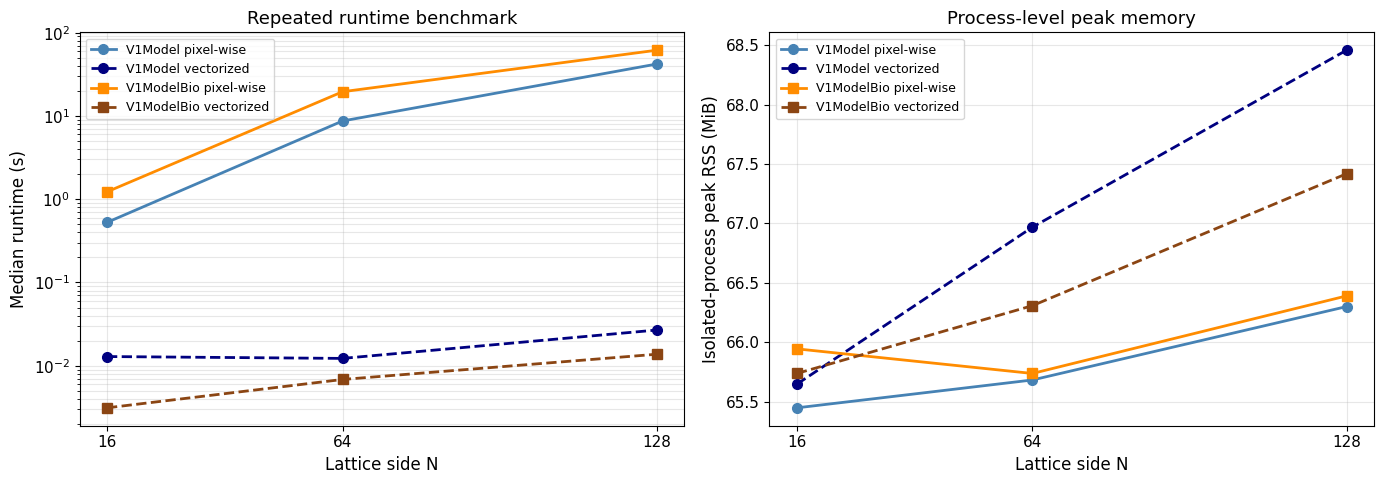

In [10]:
import json
import subprocess

BENCHMARK_SIZES = (16, 64, 128)
BENCHMARK_ITERS = 3
BENCHMARK_WARMUPS = 1
BENCHMARK_REPEATS = 3
BENCHMARK_NOTEBOOK = Path("bayes_markov_orientation_selectivity.ipynb")
if not BENCHMARK_NOTEBOOK.exists():
    raise FileNotFoundError(
        "Run this benchmark from the repository directory containing "
        f"{BENCHMARK_NOTEBOOK.name}."
    )

# A fresh interpreter is used for every implementation/size pair. This avoids the
# cumulative nature of ru_maxrss inside the notebook kernel and keeps process startup
# outside the measured model runtimes.
BENCHMARK_WORKER_CODE = r'''
import contextlib
import gc
import io
import json
from pathlib import Path
import resource
import sys
import time
import tracemalloc

import numpy as np

notebook_path = Path(sys.argv[1])
class_name = sys.argv[2]
size = int(sys.argv[3])
width = int(sys.argv[4])
iterations = int(sys.argv[5])
warmups = int(sys.argv[6])
repeats = int(sys.argv[7])
beta = float(sys.argv[8])
gamma = float(sys.argv[9])
threshold = float(sys.argv[10])

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
namespace = {}
with contextlib.redirect_stdout(io.StringIO()):
    for cell_index in (1, 3, 4, 5, 9, 10):
        exec("".join(notebook["cells"][cell_index]["source"]), namespace)

stimulus = namespace["generate_oriented_bar"](
    size, orientation_deg=0, bar_width=width
)
lgn = namespace["prepare_lgn_input"](stimulus, preprocess=True)
model_class = namespace[class_name]
model = model_class(size, beta, gamma, threshold)

for _ in range(warmups):
    model.forward(lgn, iterations)

def rss_to_mib(raw_value):
    divisor = 1024.0**2 if sys.platform == "darwin" else 1024.0
    return float(raw_value / divisor)

gc.collect()
rss_before = rss_to_mib(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss)
tracemalloc.start()
tracemalloc.reset_peak()
timings = []
for _ in range(repeats):
    start = time.perf_counter()
    model.forward(lgn, iterations)
    timings.append(time.perf_counter() - start)
_, python_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
rss_peak = rss_to_mib(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss)

print(json.dumps({
    "timings": timings,
    "rss_before_mib": rss_before,
    "peak_rss_mib": rss_peak,
    "rss_growth_mib": max(0.0, rss_peak - rss_before),
    "python_peak_mib": python_peak / 1024.0**2,
}))
'''


def run_isolated_benchmark(class_name, size, width):
    completed = subprocess.run(
        [
            sys.executable, "-c", BENCHMARK_WORKER_CODE,
            str(BENCHMARK_NOTEBOOK), class_name, str(size), str(width),
            str(BENCHMARK_ITERS), str(BENCHMARK_WARMUPS), str(BENCHMARK_REPEATS),
            str(BETA), str(GAMMA), str(T),
        ],
        check=False,
        capture_output=True,
        text=True,
        timeout=1800,
        env={**os.environ, "MPLCONFIGDIR": os.environ.get("MPLCONFIGDIR", tempfile.gettempdir())},
    )
    if completed.returncode != 0:
        raise RuntimeError(
            f"Benchmark failed for {class_name}, N={size}:\n{completed.stderr}"
        )
    try:
        return json.loads(completed.stdout.strip().splitlines()[-1])
    except (IndexError, json.JSONDecodeError) as error:
        raise RuntimeError(
            f"Invalid benchmark output for {class_name}, N={size}: "
            f"{completed.stdout!r}\n{completed.stderr}"
        ) from error


BENCHMARK_RECORDS = []
BENCHMARK_EQUALITY = {}
benchmark_models = [
    ("V1Model", "pixel-wise", V1Model),
    ("V1Model", "vectorized", V1ModelVec),
    ("V1ModelBio", "pixel-wise", V1ModelBio),
    ("V1ModelBio", "vectorized", V1ModelBioVec),
]

for size in BENCHMARK_SIZES:
    width = max(2, int(round(BAR_WIDTH * size / GRID_SIZE)))
    stimulus = generate_oriented_bar(size, orientation_deg=0, bar_width=width)
    lgn_benchmark = prepare_lgn_input(stimulus, preprocess=True)

    # Equality is tested separately from the measured repetitions.
    base_pixel = V1Model(size, BETA, GAMMA, T).forward(lgn_benchmark, BENCHMARK_ITERS)
    base_vector = V1ModelVec(size, BETA, GAMMA, T).forward(lgn_benchmark, BENCHMARK_ITERS)
    bio_pixel = V1ModelBio(size, BETA, GAMMA, T).forward(lgn_benchmark, BENCHMARK_ITERS)
    bio_vector = V1ModelBioVec(size, BETA, GAMMA, T).forward(lgn_benchmark, BENCHMARK_ITERS)
    np.testing.assert_array_equal(base_pixel, base_vector)
    np.testing.assert_array_equal(bio_pixel, bio_vector)
    BENCHMARK_EQUALITY[("V1Model", size)] = True
    BENCHMARK_EQUALITY[("V1ModelBio", size)] = True

    for family, implementation, model_class in benchmark_models:
        result = run_isolated_benchmark(model_class.__name__, size, width)
        timings = np.asarray(result["timings"], dtype=float)
        q1, q3 = np.percentile(timings, [25, 75])
        BENCHMARK_RECORDS.append({
            "family": family,
            "implementation": implementation,
            "size": size,
            "median_s": float(np.median(timings)),
            "iqr_s": float(q3 - q1),
            "peak_rss_mib": result["peak_rss_mib"],
            "rss_growth_mib": result["rss_growth_mib"],
            "python_peak_mib": result["python_peak_mib"],
        })

print(
    f"Benchmark: {BENCHMARK_WARMUPS} warm-up + {BENCHMARK_REPEATS} measured runs; "
    f"K={BENCHMARK_ITERS} MAP sweeps."
)
print(
    f"{'Model':<12} {'Implementation':<12} {'N':>4} {'Median(s)':>11} "
    f"{'IQR(s)':>10} {'Peak RSS':>11} {'RSS growth':>11} {'Py peak':>10}"
)
print("-" * 99)
for record in BENCHMARK_RECORDS:
    print(
        f"{record['family']:<12} {record['implementation']:<12} {record['size']:>4d} "
        f"{record['median_s']:>11.5f} {record['iqr_s']:>10.5f} "
        f"{record['peak_rss_mib']:>9.1f} MiB {record['rss_growth_mib']:>8.1f} MiB "
        f"{record['python_peak_mib']:>7.2f} MiB"
    )

for family in ("V1Model", "V1ModelBio"):
    for size in BENCHMARK_SIZES:
        pixel = next(
            record for record in BENCHMARK_RECORDS
            if record["family"] == family
            and record["implementation"] == "pixel-wise"
            and record["size"] == size
        )
        vector = next(
            record for record in BENCHMARK_RECORDS
            if record["family"] == family
            and record["implementation"] == "vectorized"
            and record["size"] == size
        )
        speedup = pixel["median_s"] / max(vector["median_s"], 1e-12)
        print(f"{family:<12} N={size:>3}: median vectorization speedup = {speedup:8.1f}x")

BENCHMARK_SCALING = []
for family in ("V1Model", "V1ModelBio"):
    for implementation in ("pixel-wise", "vectorized"):
        t64 = next(
            record["median_s"] for record in BENCHMARK_RECORDS
            if record["family"] == family
            and record["implementation"] == implementation
            and record["size"] == 64
        )
        t128 = next(
            record["median_s"] for record in BENCHMARK_RECORDS
            if record["family"] == family
            and record["implementation"] == implementation
            and record["size"] == 128
        )
        growth = t128 / t64
        effective_exponent = np.log(growth) / np.log(2.0)
        normalized_growth = growth / 4.0
        BENCHMARK_SCALING.append({
            "family": family,
            "implementation": implementation,
            "growth": growth,
            "effective_exponent": effective_exponent,
            "normalized_growth": normalized_growth,
        })

print("\nFinite-range timing growth from recorded N=64 and N=128 medians:")
print(f"{'Model':<12} {'Implementation':<12} {'t128/t64':>10} {'p64→128':>10} {'q64→128':>10}")
print("-" * 58)
for record in BENCHMARK_SCALING:
    print(
        f"{record['family']:<12} {record['implementation']:<12} "
        f"{record['growth']:>10.2f} {record['effective_exponent']:>10.2f} "
        f"{record['normalized_growth']:>10.2f}"
    )

fig, (ax_runtime, ax_memory) = plt.subplots(1, 2, figsize=(14, 5))
styles = {
    ("V1Model", "pixel-wise"): ("o-", "steelblue"),
    ("V1Model", "vectorized"): ("o--", "navy"),
    ("V1ModelBio", "pixel-wise"): ("s-", "darkorange"),
    ("V1ModelBio", "vectorized"): ("s--", "saddlebrown"),
}
for (family, implementation), (style, color) in styles.items():
    records = [
        record for record in BENCHMARK_RECORDS
        if record["family"] == family and record["implementation"] == implementation
    ]
    sizes = [record["size"] for record in records]
    ax_runtime.plot(
        sizes, [record["median_s"] for record in records], style,
        color=color, lw=2, ms=7, label=f"{family} {implementation}",
    )
    ax_memory.plot(
        sizes, [record["peak_rss_mib"] for record in records], style,
        color=color, lw=2, ms=7, label=f"{family} {implementation}",
    )

ax_runtime.set_xlabel("Lattice side N")
ax_runtime.set_ylabel("Median runtime (s)")
ax_runtime.set_yscale("log")
ax_runtime.set_title("Repeated runtime benchmark")
ax_runtime.set_xticks(BENCHMARK_SIZES)
ax_runtime.grid(True, which="both", alpha=0.3)
ax_runtime.legend(fontsize=9)

ax_memory.set_xlabel("Lattice side N")
ax_memory.set_ylabel("Isolated-process peak RSS (MiB)")
ax_memory.set_title("Process-level peak memory")
ax_memory.set_xticks(BENCHMARK_SIZES)
ax_memory.grid(True, alpha=0.3)
ax_memory.legend(fontsize=9)

fig.tight_layout()
save_manuscript_figure(fig, "figure_02_runtime_memory_benchmark.png")
plt.show()


---
## Simulation 1: orientation selectivity

The qualitative experiment uses input-LGN-SCI triptychs at $0^\circ$, $45^\circ$,
$90^\circ$, and $105^\circ$ for manuscript Figure 3. The orientation sweep evaluates
$0^\circ$ to $180^\circ$ in $10^\circ$ steps and reports the
preferred-versus-orthogonal OSI in manuscript Figure 4.


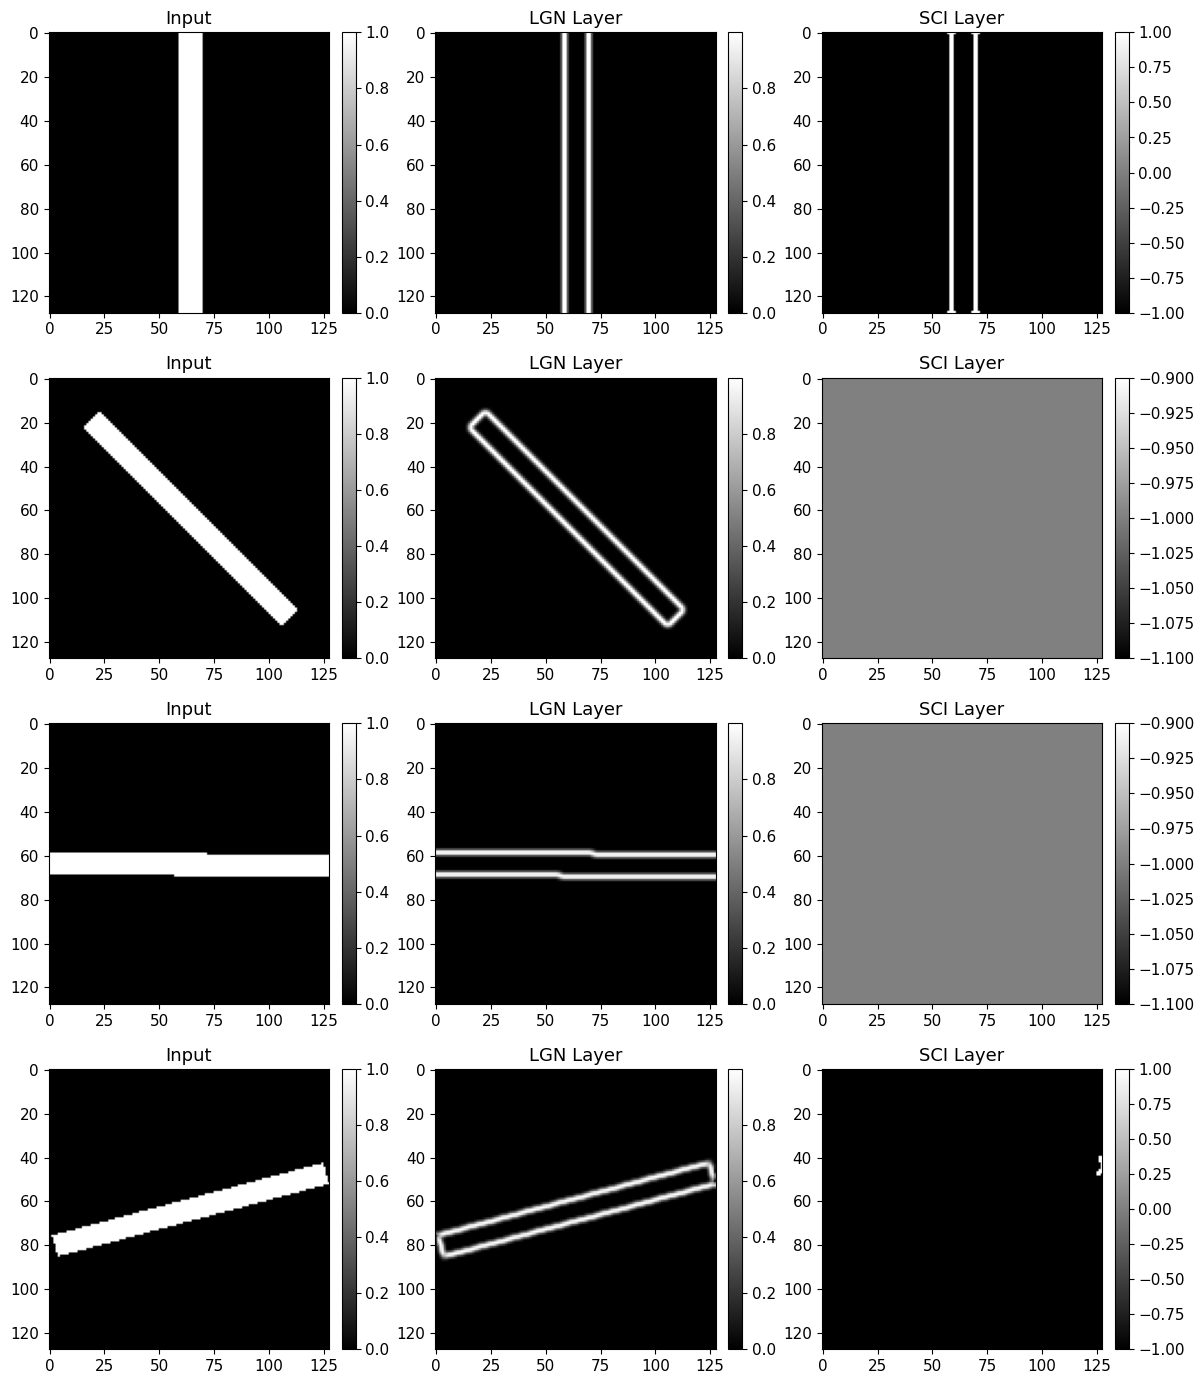

Figure 3 rows (top to bottom): 0, 45, 90, and 105 degrees.


In [11]:
model_bio_a = V1ModelBioVec(GRID_SIZE, BETA, GAMMA, T)

# Manuscript Figure 3: qualitative orientation response.
# Orientations used in the qualitative orientation comparison.
QUALITATIVE_ORIENTATIONS = [0, 45, 90, 105]
qualitative_records = []
for orientation in QUALITATIVE_ORIENTATIONS:
    stimulus = create_synthetic_bar(
        GRID_SIZE, bar_width=QUALITATIVE_BAR_WIDTH,
        orientation=orientation, contrast=1.0,
    )
    lgn = prepare_lgn_input_legacy(stimulus, preprocess=True)
    sci = model_bio_a.forward(lgn, NUM_ITERS)
    qualitative_records.append((stimulus, lgn, sci))

fig, axes = plt.subplots(len(QUALITATIVE_ORIENTATIONS), 3, figsize=(12, 14))
for row, (orientation, (stimulus, lgn, sci)) in enumerate(
    zip(QUALITATIVE_ORIENTATIONS, qualitative_records)
):
    panels = [(stimulus, "Input"), (lgn, "LGN Layer"), (sci, "SCI Layer")]
    for column, (data, title) in enumerate(panels):
        image = axes[row, column].imshow(data, cmap="gray")
        axes[row, column].set_title(title)
        fig.colorbar(image, ax=axes[row, column], fraction=0.046, pad=0.04)

fig.tight_layout()
save_manuscript_figure(fig, "figure_03_qualitative_orientation_response.png")
plt.show()

print("Figure 3 rows (top to bottom): 0, 45, 90, and 105 degrees.")


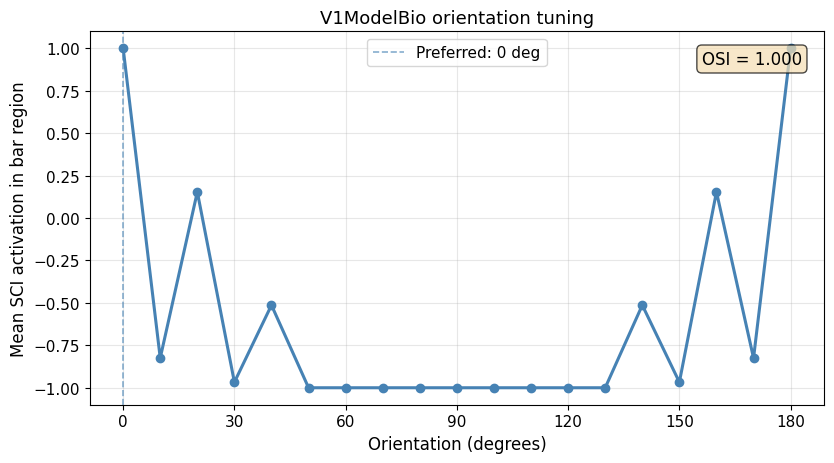

Preferred orientation : 0 deg
Two-point OSI         : 1.0000


In [12]:
# Manuscript Figure 4: quantitative tuning curve.
responses_a = []
for orientation in ORIENTATIONS:
    stimulus = generate_oriented_bar(
        GRID_SIZE, orientation_deg=orientation, bar_width=BAR_WIDTH,
        contrast=1.0, background_intensity=0.5,
    )
    lgn = prepare_lgn_input(stimulus, preprocess=True)
    sci = model_bio_a.forward(lgn, NUM_ITERS)
    responses_a.append(sci[bar_mask(stimulus)].mean())

responses_a = np.asarray(responses_a)
osi_a = compute_osi(responses_a, ORIENTATIONS, signed=True)
pref_ori_a = ORIENTATIONS[int(np.argmax(responses_a))]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(ORIENTATIONS, responses_a, "o-", color="steelblue", lw=2.2, ms=6)
ax.axvline(pref_ori_a, color="steelblue", lw=1.2, ls="--", alpha=0.65,
           label=f"Preferred: {pref_ori_a} deg")
ax.set_xlabel("Orientation (degrees)")
ax.set_ylabel("Mean SCI activation in bar region")
ax.set_title("V1ModelBio orientation tuning")
ax.set_xticks(range(0, 181, 30))
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, f"OSI = {osi_a:.3f}", transform=ax.transAxes,
        ha="right", va="top", fontsize=12,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7))
fig.tight_layout()
save_manuscript_figure(fig, "figure_04_orientation_tuning_curve.png")
plt.show()

print(f"Preferred orientation : {pref_ori_a} deg")
print(f"Two-point OSI         : {osi_a:.4f}")


---
## Simulation 2: contrast invariance and noise robustness

The qualitative contrast experiment evaluates normalized positive-contrast inputs in
manuscript Figure 5. Gaussian-noise sweeps at $0^\circ$, $10^\circ$, $45^\circ$,
and $90^\circ$ generate manuscript Figures 6–9. The same perturbed LGN array is
supplied to all four active model variants
at each noise level.
Rate-coded and spiking responses are plotted on separate axes because their units differ.


### 2.1 Qualitative normalized-input contrast response (Figure 5)

The contrast experiment uses black-background bars at contrasts $0.2$, $0.6$, and
$1.0$. Because the LGN magnitude is min-max normalized after edge extraction, positive
contrast changes can yield the same normalized LGN structure and therefore the same
inferred SCI pattern. The zero-contrast case is excluded because it contains no
stimulus.


### 2.2 Orientation-resolved noise robustness (Figures 6–9)

Noise standard deviations are 0, 0.05, 0.10, 0.20, 0.30, and 0.50. The experiment
compares two rate-coded variants (`V1Model`, `V1ModelBio`) and two downstream spiking
readouts (LIF, HH). No fifth dynamical model is active in the reported comparison.


### 2.3 Cross-model comparison (Figures 10–11)

The side-by-side maps and tuning curves compare the same four active variants under a
shared parameter setting. This is a common-operating-point comparison, not a claim that
each model has been individually optimized.


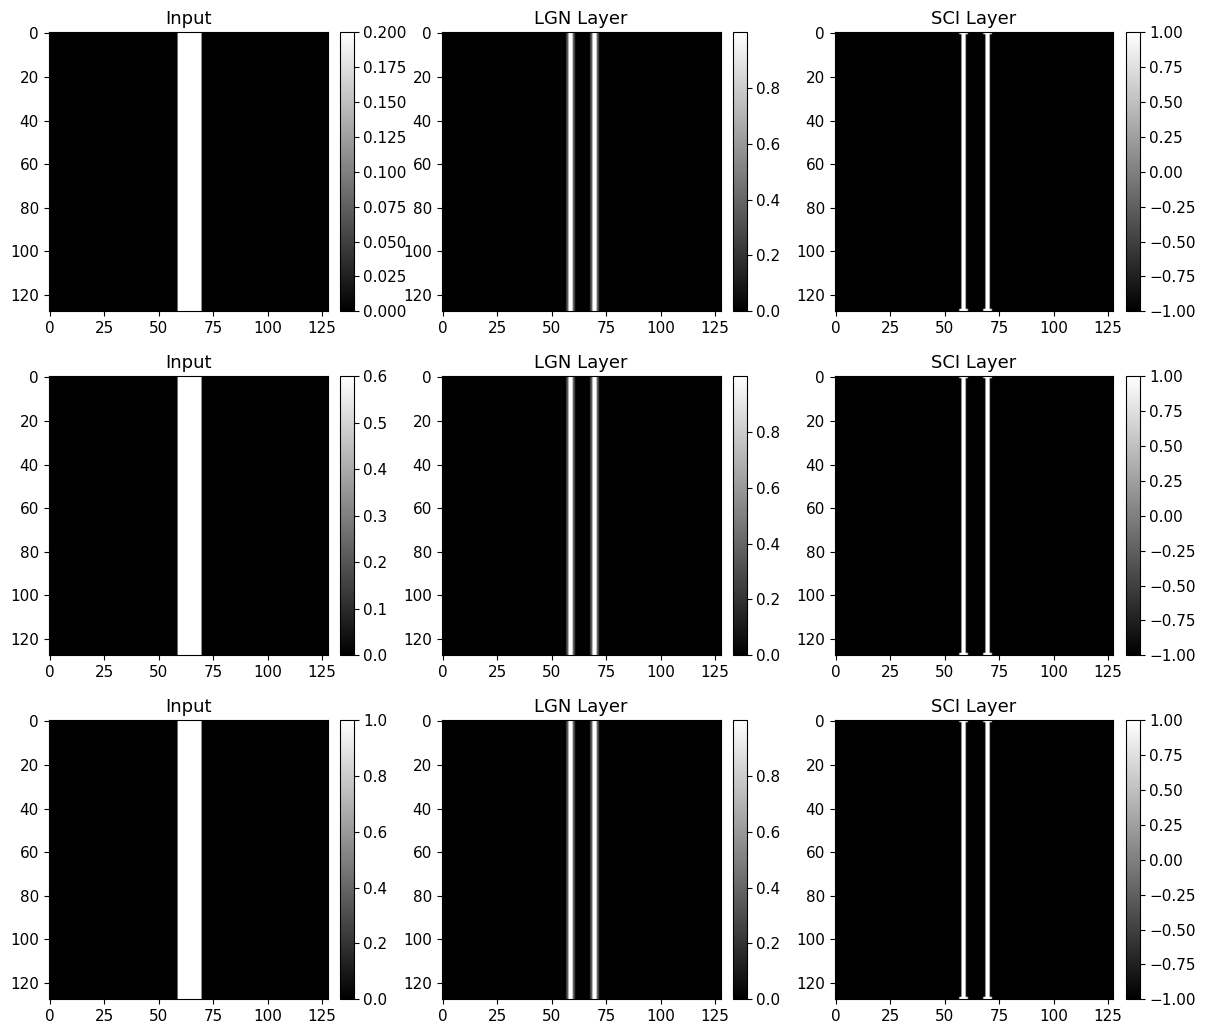

Contrast 0.2: SCI pixels differing from contrast 1.0 = 0
Contrast 0.6: SCI pixels differing from contrast 1.0 = 0
Contrast 1.0: SCI pixels differing from contrast 1.0 = 0
Figure 5 rows (top to bottom): contrasts 0.2, 0.6, and 1.0.


In [13]:
# Manuscript Figure 5: normalized-input contrast response.
# Positive contrast levels used in the qualitative contrast comparison.
CONTRAST_LEVELS = [0.2, 0.6, 1.0]
contrast_records = []

for contrast in CONTRAST_LEVELS:
    stimulus = create_synthetic_bar(
        GRID_SIZE, bar_width=QUALITATIVE_BAR_WIDTH,
        orientation=0.0, contrast=contrast,
    )
    lgn = prepare_lgn_input_legacy(stimulus, preprocess=True)
    sci = model_bio_a.forward(lgn, NUM_ITERS)
    contrast_records.append((stimulus, lgn, sci))

fig, axes = plt.subplots(len(CONTRAST_LEVELS), 3, figsize=(12, 10.5))
for row, (contrast, (stimulus, lgn, sci)) in enumerate(zip(CONTRAST_LEVELS, contrast_records)):
    panels = [(stimulus, "Input"), (lgn, "LGN Layer"), (sci, "SCI Layer")]
    for column, (data, title) in enumerate(panels):
        image = axes[row, column].imshow(data, cmap="gray")
        axes[row, column].set_title(title)
        fig.colorbar(image, ax=axes[row, column], fraction=0.046, pad=0.04)

fig.tight_layout()
save_manuscript_figure(fig, "figure_05_normalized_input_contrast.png")
plt.show()

reference_sci = contrast_records[-1][2]
for contrast, (_, _, sci) in zip(CONTRAST_LEVELS, contrast_records):
    mismatch = int(np.count_nonzero(sci != reference_sci))
    print(f"Contrast {contrast:.1f}: SCI pixels differing from contrast 1.0 = {mismatch}")
print("Figure 5 rows (top to bottom): contrasts 0.2, 0.6, and 1.0.")


---
## LIF downstream readout

`V1ModelSpiking` is a leaky integrate-and-fire comparison readout. It receives the
MAP-derived current rather than raw LGN evidence. The reported firing-rate maps and
rasters in manuscript Figure 13 show how the already inferred field can be expressed
by spikes; they do not
show that LIF dynamics infer orientation selectivity.


Preferred  (0°):  48.9 Hz
Orthogonal (90°): 0.0 Hz
Firing-rate spread: 4 distinct rates, std=0.0031
Active-cell firing rate: mean=48.9 Hz, std=3.1 Hz, CV=0.063


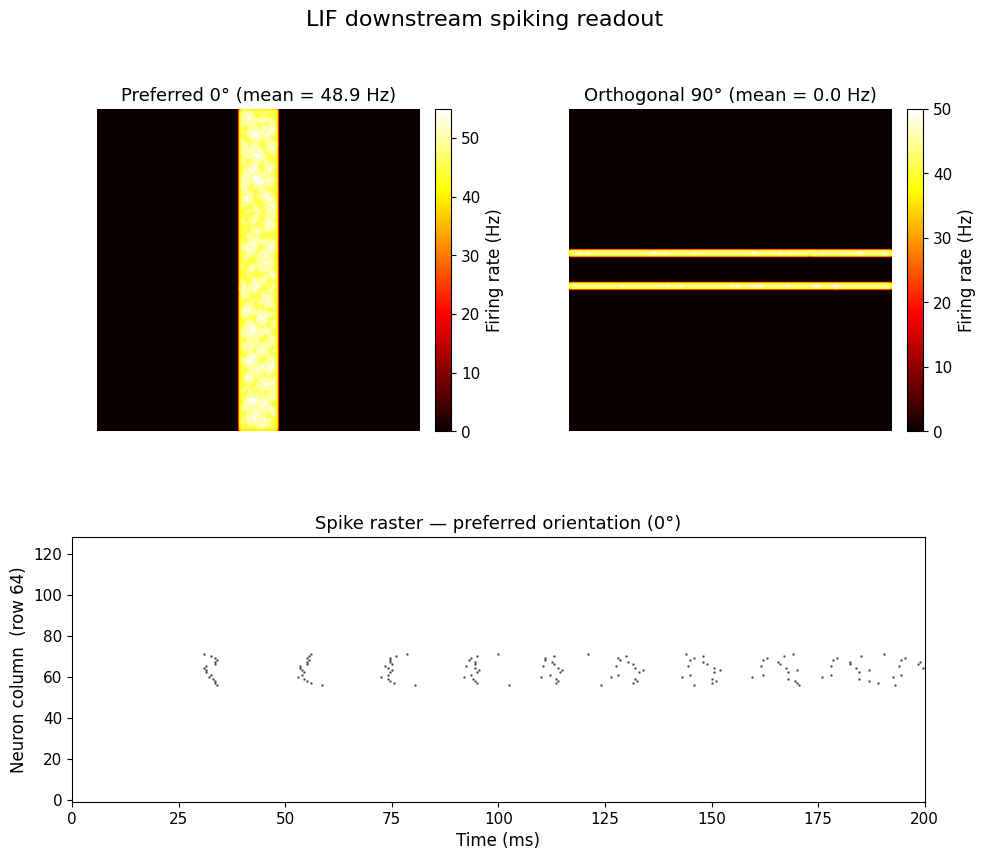

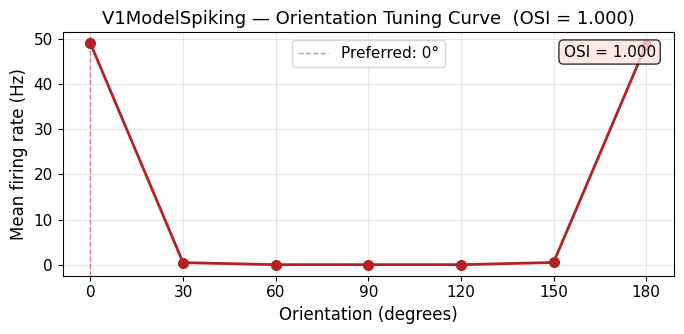


Preferred orientation : 0°
OSI (spiking model)   : 1.0000

   Ori   Rate (Hz)
     0       49.08
    30        0.45
    60        0.00
    90        0.00
   120        0.00
   150        0.48
   180       48.80


In [14]:
np.random.seed(RANDOM_SEED + 10)

# SPK_PARAMS is declared in the global parameter cell.
model_spk = V1ModelSpiking(GRID_SIZE, **SPK_PARAMS)

# ── 0° run (preferred) ────────────────────────────────────────────────────
stim_0   = generate_oriented_bar(GRID_SIZE, orientation_deg=0,  bar_width=BAR_WIDTH)
lgn_0    = prepare_lgn_input(stim_0, preprocess=True)
rate_0   = model_spk.forward(lgn_0)
raster_0 = model_spk.last_raster

# ── 90° run (orthogonal) ─────────────────────────────────────────────────
stim_90 = generate_oriented_bar(GRID_SIZE, orientation_deg=90, bar_width=BAR_WIDTH)
lgn_90  = prepare_lgn_input(stim_90, preprocess=True)
rate_90 = model_spk.forward(lgn_90)

R0  = rate_0[bar_mask(stim_0)].mean()
R90 = rate_90[bar_mask(stim_90)].mean()
print(f"Preferred  (0°):  {R0*1000:.1f} Hz")
print(f"Orthogonal (90°): {R90*1000:.1f} Hz")

# ── Firing-rate dispersion / CV report ───────────────────────────────────────────────
bar_rates  = rate_0[bar_mask(stim_0)]
n_distinct = len(np.unique(np.round(bar_rates, 3)))
assert rate_0.min() >= 0.0, "Firing rates must be non-negative"
print(f"Firing-rate spread: {n_distinct} distinct rates, std={bar_rates.std():.4f}")
rates_lif  = bar_rates[bar_rates > 0] * 1000          # Hz; reused in distribution figure
cv_lif     = rates_lif.std() / rates_lif.mean() if rates_lif.mean() > 0 else 0.0
print(f"Active-cell firing rate: mean={rates_lif.mean():.1f} Hz, "
      f"std={rates_lif.std():.1f} Hz, CV={cv_lif:.3f}")

# ── Manuscript Figure 13: firing-rate maps + spike raster ────────────────────────────
fig = plt.figure(figsize=(11, 9))
grid = fig.add_gridspec(2, 2, height_ratios=(1.0, 0.82), hspace=0.36, wspace=0.24)
ax_pref = fig.add_subplot(grid[0, 0])
ax_orth = fig.add_subplot(grid[0, 1])
ax_r = fig.add_subplot(grid[1, :])

im0 = ax_pref.imshow(rate_0 * 1000, cmap='hot', vmin=0)
ax_pref.set_title(f'Preferred 0° (mean = {R0*1000:.1f} Hz)')
ax_pref.axis('off')
fig.colorbar(im0, ax=ax_pref, label='Firing rate (Hz)', fraction=0.046, pad=0.04)

im1 = ax_orth.imshow(rate_90 * 1000, cmap='hot', vmin=0)
ax_orth.set_title(f'Orthogonal 90° (mean = {R90*1000:.1f} Hz)')
ax_orth.axis('off')
fig.colorbar(im1, ax=ax_orth, label='Firing rate (Hz)', fraction=0.046, pad=0.04)

for j, times in enumerate(raster_0):
    if times:
        ax_r.scatter(times, [j] * len(times), s=0.8, c='k', alpha=0.5)
ax_r.set_xlabel('Time (ms)')
ax_r.set_ylabel(f'Neuron column  (row {model_spk.raster_row})')
ax_r.set_title('Spike raster — preferred orientation (0°)')
ax_r.set_xlim(0, model_spk.T_total)
ax_r.set_ylim(-1, GRID_SIZE)

fig.suptitle('LIF downstream spiking readout', fontsize=16, y=0.99)
save_manuscript_figure(fig, 'figure_13_lif_spiking_readout.png')
plt.show()

# ── Supplementary 7-orientation tuning curve ────────────────────────────────
ORIS_SPK      = list(range(0, 181, 30))
responses_spk = []

for ori in ORIS_SPK:
    stim_i = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH)
    lgn_i  = prepare_lgn_input(stim_i, preprocess=True)
    rate_i = model_spk.forward(lgn_i)
    responses_spk.append(rate_i[bar_mask(stim_i)].mean())

responses_spk = np.array(responses_spk)
# signed=False: firing rates are already ≥ 0, no [-1,+1] remapping needed
osi_spk      = compute_osi(responses_spk, ORIS_SPK, signed=False)
pref_ori_spk = ORIS_SPK[int(np.argmax(responses_spk))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ORIS_SPK, responses_spk * 1000, 'o-', color='firebrick', lw=2, ms=7)
ax.axvline(pref_ori_spk, color='firebrick', lw=1, ls='--', alpha=0.5,
           label=f'Preferred: {pref_ori_spk}°')
ax.set_xlabel('Orientation (degrees)')
ax.set_ylabel('Mean firing rate (Hz)')
ax.set_title(f'V1ModelSpiking — Orientation Tuning Curve  (OSI = {osi_spk:.3f})')
ax.set_xticks(range(0, 181, 30))
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, f'OSI = {osi_spk:.3f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.8))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_lif_tuning_curve.png', dpi=OUTPUT_DPI)
plt.show()

print(f"\nPreferred orientation : {pref_ori_spk}°")
print(f"OSI (spiking model)   : {osi_spk:.4f}")
print(f"\n{'Ori':>6}  {'Rate (Hz)':>10}")
for ori, r in zip(ORIS_SPK, responses_spk):
    print(f"{ori:6d}  {r*1000:10.2f}")


### LIF readout with per-neuron gain heterogeneity

A fixed gain sampled uniformly from 0.85 to 1.15 multiplies each neuron's MAP-derived
current. The resulting firing-rate spread is a parameter-dependent property of this LIF
readout and is reported descriptively; it is not interpreted as evidence for a temporal
code.


Preferred  (0°):  53.9 Hz
Orthogonal (90°): 0.0 Hz
Firing-rate spread: 7 distinct rates, std=0.0055
Active-cell firing rate: mean=53.9 Hz, std=5.5 Hz, CV=0.103


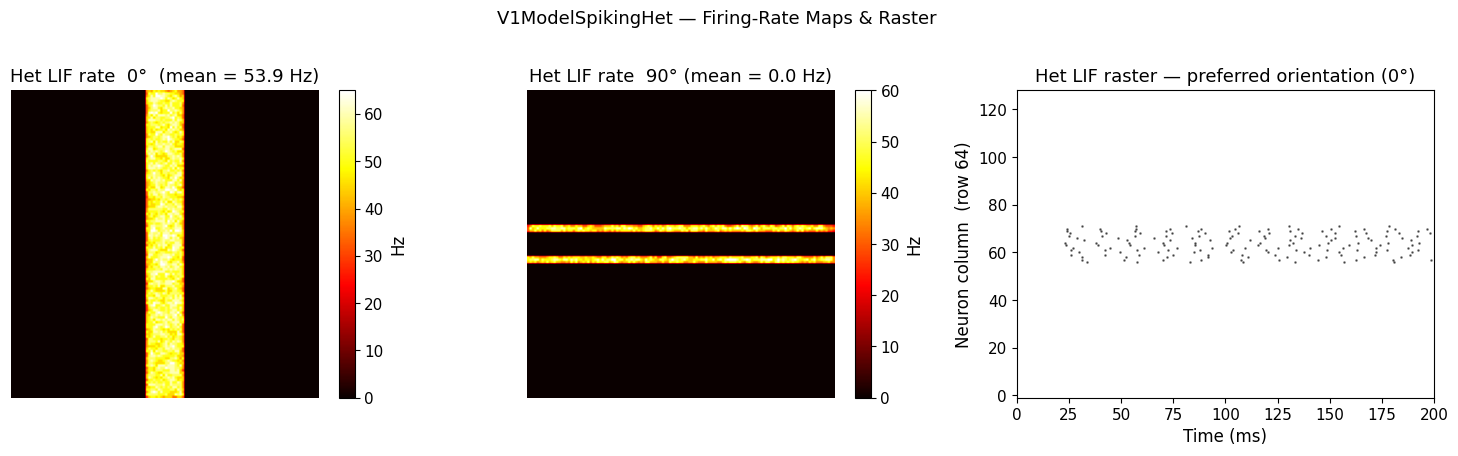

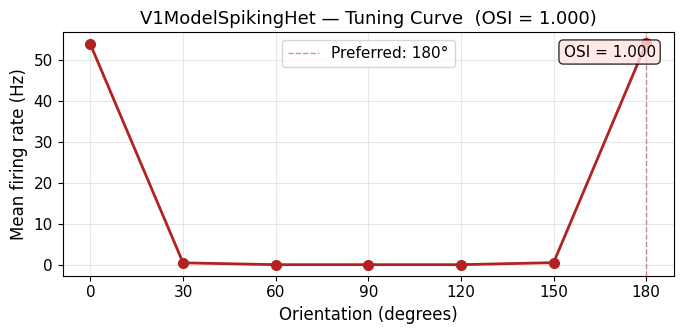


Preferred orientation : 180°
OSI (het LIF model)   : 1.0000

   Ori   Rate (Hz)
     0       53.81
    30        0.44
    60        0.00
    90        0.00
   120        0.00
   150        0.49
   180       54.06


In [15]:
class V1ModelSpikingHet(V1ModelSpiking):
    """V1ModelSpiking with static per-neuron input-current gain (heterogeneity)."""

    def forward(self, lgn_layer):
        lgn = lgn_layer.astype(float)
        N   = self.grid_size

        # Initialise gain map once; re-used across orientation sweeps
        if getattr(self, 'cell_gain', None) is None:
            rng = np.random.default_rng(123)
            self.cell_gain = rng.uniform(*HETEROGENEITY_RANGE, (N, N))

        # Stage 1: MAP orientation field (call V1ModelBioVec directly to skip
        # V1ModelSpiking.forward and obtain only the ±1 sci_map)
        sci_map = V1ModelBioVec.forward(self, lgn_layer, self.num_iters_map)

        # Stage 2: heterogeneous drive — gain multiplies the whole I_lgn term
        I_lgn = (self.I_offset + self.I_scale * sci_map) * self.cell_gain

        V              = np.full((N, N), self.V_rest,  dtype=float)
        refractory     = np.zeros((N, N),              dtype=int)
        synaptic_trace = np.zeros((N, N),              dtype=float)
        spike_count    = np.zeros((N, N),              dtype=float)
        syn_decay      = np.exp(-self.dt / self.tau_syn)
        raster         = [[] for _ in range(N)]

        for step in range(self.n_steps):
            t = step * self.dt
            I_total = I_lgn + self.gamma_lat * synaptic_trace
            if self.noise_sigma > 0:
                I_total = I_total + np.random.normal(0, self.noise_sigma, (N, N))

            dV    = (self.dt / self.tau_m) * (-(V - self.V_rest) + I_total)
            V_new = np.where(refractory > 0, self.V_reset, V + dV)

            spikes = (V_new >= self.V_threshold) & (refractory == 0)
            V_new  = np.where(spikes, self.V_reset, V_new)

            refractory          = np.maximum(0, refractory - 1)
            refractory[spikes]  = self.t_ref_steps
            spike_count        += spikes

            for c in np.where(spikes[self.raster_row])[0]:
                raster[c].append(t)

            synaptic_trace *= syn_decay
            sp_pad = np.pad(spikes.astype(float), 1, mode='constant', constant_values=0)
            synaptic_trace += (
                sp_pad[1:-1, :-2] + sp_pad[1:-1,  2:]
              + sp_pad[:-2, 1:-1] + sp_pad[2:,  1:-1]
              + sp_pad[:-2, :-2]  + sp_pad[:-2,  2:]
              + sp_pad[2:,  :-2]  + sp_pad[2:,   2:]
            )
            V = V_new

        self.last_raster = raster
        return spike_count / self.T_total


np.random.seed(RANDOM_SEED + 20)

model_spk_het = V1ModelSpikingHet(GRID_SIZE, **SPK_PARAMS)

# ── 0° run ────────────────────────────────────────────────────────
stim_0h   = generate_oriented_bar(GRID_SIZE, orientation_deg=0,  bar_width=BAR_WIDTH)
lgn_0h    = prepare_lgn_input(stim_0h, preprocess=True)
rate_0h   = model_spk_het.forward(lgn_0h)
raster_0h = model_spk_het.last_raster

# ── 90° run ───────────────────────────────────────────────────────
stim_90h = generate_oriented_bar(GRID_SIZE, orientation_deg=90, bar_width=BAR_WIDTH)
lgn_90h  = prepare_lgn_input(stim_90h, preprocess=True)
rate_90h = model_spk_het.forward(lgn_90h)

R0h  = rate_0h[bar_mask(stim_0h)].mean()
R90h = rate_90h[bar_mask(stim_90h)].mean()
print(f"Preferred  (0°):  {R0h*1000:.1f} Hz")
print(f"Orthogonal (90°): {R90h*1000:.1f} Hz")

# ── Spread / CV report ─────────────────────────────────────────────
bar_rates_h   = rate_0h[bar_mask(stim_0h)]
n_distinct_h  = len(np.unique(np.round(bar_rates_h, 3)))
assert rate_0h.min() >= 0.0
print(f"Firing-rate spread: {n_distinct_h} distinct rates, std={bar_rates_h.std():.4f}")
rates_lif_het = bar_rates_h[bar_rates_h > 0] * 1000   # Hz; reused in distribution figure
cv_lif_het    = rates_lif_het.std() / rates_lif_het.mean() if rates_lif_het.mean() > 0 else 0.0
print(f"Active-cell firing rate: mean={rates_lif_het.mean():.1f} Hz, "
      f"std={rates_lif_het.std():.1f} Hz, CV={cv_lif_het:.3f}")

# ── Supplementary maps + raster ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

im0 = axes[0].imshow(rate_0h * 1000, cmap='hot', vmin=0)
axes[0].set_title(f'Het LIF rate  0°  (mean = {R0h*1000:.1f} Hz)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], label='Hz')

im1 = axes[1].imshow(rate_90h * 1000, cmap='hot', vmin=0)
axes[1].set_title(f'Het LIF rate  90° (mean = {R90h*1000:.1f} Hz)')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], label='Hz')

ax_r = axes[2]
for j, times in enumerate(raster_0h):
    if times:
        ax_r.scatter(times, [j] * len(times), s=0.8, c='k', alpha=0.5)
ax_r.set_xlabel('Time (ms)')
ax_r.set_ylabel(f'Neuron column  (row {model_spk_het.raster_row})')
ax_r.set_title('Het LIF raster — preferred orientation (0°)')
ax_r.set_xlim(0, model_spk_het.T_total)
ax_r.set_ylim(-1, GRID_SIZE)

plt.suptitle('V1ModelSpikingHet — Firing-Rate Maps & Raster', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_lif_heterogeneity_maps.png', dpi=OUTPUT_DPI, bbox_inches='tight')
plt.show()

# ── Supplementary tuning curve ────────────────────────────────────────
ORIS_SPK_H     = list(range(0, 181, 30))
responses_spkh = []

for ori in ORIS_SPK_H:
    stim_i = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH)
    lgn_i  = prepare_lgn_input(stim_i, preprocess=True)
    rate_i = model_spk_het.forward(lgn_i)
    responses_spkh.append(rate_i[bar_mask(stim_i)].mean())

responses_spkh = np.array(responses_spkh)
osi_spkh       = compute_osi(responses_spkh, ORIS_SPK_H, signed=False)
pref_ori_spkh  = ORIS_SPK_H[int(np.argmax(responses_spkh))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ORIS_SPK_H, responses_spkh * 1000, 'o-', color='firebrick', lw=2, ms=7)
ax.axvline(pref_ori_spkh, color='firebrick', lw=1, ls='--', alpha=0.5,
           label=f'Preferred: {pref_ori_spkh}°')
ax.set_xlabel('Orientation (degrees)')
ax.set_ylabel('Mean firing rate (Hz)')
ax.set_title(f'V1ModelSpikingHet — Tuning Curve  (OSI = {osi_spkh:.3f})')
ax.set_xticks(range(0, 181, 30))
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, f'OSI = {osi_spkh:.3f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.8))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_lif_heterogeneity_tuning.png', dpi=OUTPUT_DPI)
plt.show()

print(f"\nPreferred orientation : {pref_ori_spkh}°")
print(f"OSI (het LIF model)   : {osi_spkh:.4f}")
print(f"\n{'Ori':>6}  {'Rate (Hz)':>10}")
for ori, r in zip(ORIS_SPK_H, responses_spkh):
    print(f"{ori:6d}  {r*1000:10.2f}")


---
## Hodgkin-Huxley downstream readout

The HH readout uses the standard conductance equation

$$
C_m\frac{dV}{dt}=I_{\mathrm{total}}-g_{\mathrm{Na}}m^3h(V-E_{\mathrm{Na}})
-g_{\mathrm K}n^4(V-E_{\mathrm K})-g_L(V-E_L),
$$

with standard gating-variable dynamics. It receives the same two-stage MAP-derived
drive as the LIF model. With the declared parameters, preferred sites receive
$8\,\mu\mathrm{A}/\mathrm{cm}^2$ and non-preferred sites receive
$2\,\mu\mathrm{A}/\mathrm{cm}^2$ before lateral and noise terms. Spikes are counted at
upward $0$-mV crossings. The model uses $\Delta t=0.05\,\mathrm{ms}$ for
$150\,\mathrm{ms}$ per stimulus.

Manuscript Figure 12 summarizes the preferred and orthogonal response maps and spike
raster. The HH neuron provides a biophysical spike generator, but its dynamics do not compute
the Bayes-Markov MAP field in this notebook.


In [16]:
class V1ModelHH(V1ModelBioVec):
    """
    Hodgkin-Huxley spiking model on the V1 cortical grid.

    Two-stage design (identical to V1ModelSpiking):
      Stage 1 — MAP inference: sci_map = super().forward(lgn, num_iters_map)  {−1, +1}
      Stage 2 — HH dynamics:  I_lgn = I_offset + I_scale * sci_map  (µA/cm²)
                               z(t+dt) = exp(-dt/tau_syn)*z(t) + sum(neighbor spikes)
                               I_total = I_lgn + gamma_lat*z + N(0, noise_sigma)

    Standard HH parameters (modern absolute-mV convention):
      C_m=1 µF/cm²,  g_Na=120, g_K=36, g_L=0.3 mS/cm²
      E_Na=+50, E_K=−77, E_L=−54.387 mV,  V_rest=−65 mV

    Drive:  I_offset=5.0, I_scale=3.0 µA/cm²
      Preferred  (sci=+1): I = 8.0 µA/cm² > rheobase (≈6.2) → fires autonomously
      Non-preferred (sci=−1): I = 2.0 µA/cm² < rheobase → sub-threshold

    noise_sigma=0.8 microA/cm^2 adds independent per-step current noise.
    Reported rate concentration is specific to this drive range and duration.
    """

    def __init__(self, grid_size, beta=1.0, T=0.15,
                 gamma_map=2.0, num_iters_map=12,
                 C_m=1.0, g_Na=120.0, g_K=36.0, g_L=0.3,
                 E_Na=50.0, E_K=-77.0, E_L=-54.387, V_rest=-65.0,
                 tau_syn=8.0, dt=0.05, T_total=150.0,
                 I_offset=5.0, I_scale=3.0, gamma_lat=0.3,
                 noise_sigma=0.8, spike_threshold=0.0, raster_row=None):
        super().__init__(grid_size, beta=beta, gamma=gamma_map, T=T)
        self.num_iters_map   = num_iters_map
        self.C_m             = C_m
        self.g_Na = g_Na;  self.g_K = g_K;  self.g_L = g_L
        self.E_Na = E_Na;  self.E_K = E_K;  self.E_L = E_L
        self.V_rest          = V_rest
        self.tau_syn         = tau_syn
        self.dt              = dt
        self.T_total         = T_total
        self.n_steps         = int(round(T_total / dt))
        self.I_offset        = I_offset
        self.I_scale         = I_scale
        self.gamma_lat       = gamma_lat
        self.noise_sigma     = noise_sigma
        self.spike_threshold = spike_threshold
        self.raster_row      = raster_row if raster_row is not None else grid_size // 2
        self.last_raster     = None

    def _alpha_m(self, V):
        dv = V + 40.0
        return np.where(np.abs(dv) < 1e-7, 1.0, 0.1 * dv / (1.0 - np.exp(-dv / 10.0)))

    def _beta_m(self, V):
        return 4.0 * np.exp(-(V + 65.0) / 18.0)

    def _alpha_h(self, V):
        return 0.07 * np.exp(-(V + 65.0) / 20.0)

    def _beta_h(self, V):
        return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))

    def _alpha_n(self, V):
        dv = V + 55.0
        return np.where(np.abs(dv) < 1e-7, 0.1, 0.01 * dv / (1.0 - np.exp(-dv / 10.0)))

    def _beta_n(self, V):
        return 0.125 * np.exp(-(V + 65.0) / 80.0)

    def forward(self, lgn_layer):
        lgn = lgn_layer.astype(float)
        N   = self.grid_size

        # Stage 1: MAP orientation field
        sci_map = super().forward(lgn_layer, self.num_iters_map)   # (N,N), ±1

        # Stage 2: static LGN drive (µA/cm²)
        I_lgn = self.I_offset + self.I_scale * sci_map             # (N,N)

        # Initialise HH state at steady-state gating variables
        V_arr = np.full((N, N), self.V_rest, dtype=float)
        am0, bm0 = self._alpha_m(V_arr), self._beta_m(V_arr)
        ah0, bh0 = self._alpha_h(V_arr), self._beta_h(V_arr)
        an0, bn0 = self._alpha_n(V_arr), self._beta_n(V_arr)
        m_arr = am0 / (am0 + bm0)
        h_arr = ah0 / (ah0 + bh0)
        n_arr = an0 / (an0 + bn0)

        synaptic_trace = np.zeros((N, N), dtype=float)
        spike_count    = np.zeros((N, N), dtype=float)
        syn_decay      = np.exp(-self.dt / self.tau_syn)
        raster         = [[] for _ in range(N)]
        V_prev         = V_arr.copy()
        dt, C_m        = self.dt, self.C_m

        for step in range(self.n_steps):
            t = step * dt

            I_total = I_lgn + self.gamma_lat * synaptic_trace
            if self.noise_sigma > 0:
                I_total = I_total + np.random.normal(0, self.noise_sigma, (N, N))

            I_Na = self.g_Na * m_arr**3 * h_arr * (V_arr - self.E_Na)
            I_K  = self.g_K  * n_arr**4          * (V_arr - self.E_K)
            I_L  = self.g_L                       * (V_arr - self.E_L)

            am = self._alpha_m(V_arr);  bm = self._beta_m(V_arr)
            ah = self._alpha_h(V_arr);  bh = self._beta_h(V_arr)
            an = self._alpha_n(V_arr);  bn = self._beta_n(V_arr)

            V_new = V_arr + (dt / C_m) * (I_total - I_Na - I_K - I_L)
            m_arr = np.clip(m_arr + dt * (am * (1.0 - m_arr) - bm * m_arr), 0.0, 1.0)
            h_arr = np.clip(h_arr + dt * (ah * (1.0 - h_arr) - bh * h_arr), 0.0, 1.0)
            n_arr = np.clip(n_arr + dt * (an * (1.0 - n_arr) - bn * n_arr), 0.0, 1.0)

            spikes = (V_prev < self.spike_threshold) & (V_new >= self.spike_threshold)
            spike_count += spikes
            for c in np.where(spikes[self.raster_row])[0]:
                raster[c].append(t)

            synaptic_trace *= syn_decay
            sp_pad = np.pad(spikes.astype(float), 1, mode='constant', constant_values=0)
            synaptic_trace += (
                sp_pad[1:-1, :-2] + sp_pad[1:-1,  2:]
              + sp_pad[:-2, 1:-1] + sp_pad[2:,  1:-1]
              + sp_pad[:-2, :-2]  + sp_pad[:-2,  2:]
              + sp_pad[2:,  :-2]  + sp_pad[2:,   2:]
            )
            V_prev = V_new
            V_arr  = V_new

        self.last_raster = raster
        return spike_count / self.T_total   # spikes/ms, shape (N,N), ≥ 0


---
## Baseline Hodgkin-Huxley readout

This experiment measures non-negative spike-count rates after applying the MAP-derived
drive. Under the selected current range, duration, and discretization, active HH cells
produce a narrowly concentrated set of rates. This result is not sufficient to establish
intrinsic firing-rate bistability, temporal coding, or a mechanistic implementation of
the inference; it is a property of the tested HH readout regime.


Preferred  (0°):  66.7 Hz
Orthogonal (90°): 0.0 Hz
Firing-rate spread: 1 distinct rates, std=0.0000
Active-cell firing rate: mean=66.7 Hz, std=0.0 Hz, CV=0.000


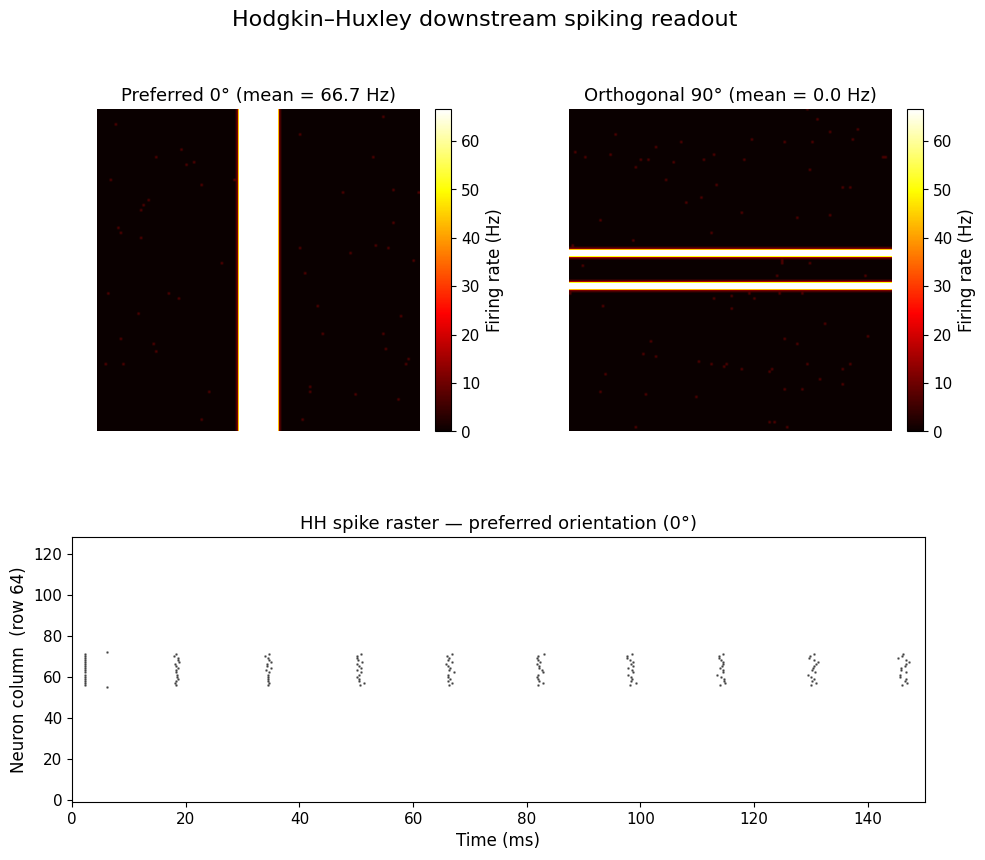

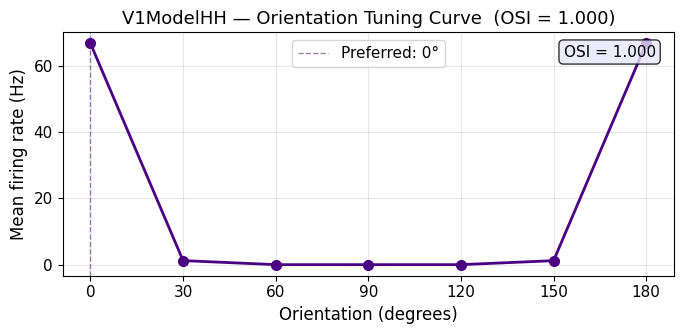


Preferred orientation : 0°
OSI (HH model)        : 0.9996

   Ori   Rate (Hz)
     0       66.67
    30        1.24
    60        0.02
    90        0.01
   120        0.02
   150        1.22
   180       66.67


In [17]:
np.random.seed(RANDOM_SEED + 30)

# HH_PARAMS is declared in the global parameter cell.
model_hh = V1ModelHH(GRID_SIZE, **HH_PARAMS)

# ── 0° run (preferred) ────────────────────────────────────────────────────
stim_0    = generate_oriented_bar(GRID_SIZE, orientation_deg=0,  bar_width=BAR_WIDTH)
lgn_0     = prepare_lgn_input(stim_0, preprocess=True)
rate_hh0  = model_hh.forward(lgn_0)
raster_hh = model_hh.last_raster

# ── 90° run (orthogonal) ─────────────────────────────────────────────────
stim_90   = generate_oriented_bar(GRID_SIZE, orientation_deg=90, bar_width=BAR_WIDTH)
lgn_90    = prepare_lgn_input(stim_90, preprocess=True)
rate_hh90 = model_hh.forward(lgn_90)

R0  = rate_hh0[bar_mask(stim_0)].mean()
R90 = rate_hh90[bar_mask(stim_90)].mean()
print(f"Preferred  (0°):  {R0*1000:.1f} Hz")
print(f"Orthogonal (90°): {R90*1000:.1f} Hz")

# ── Firing-rate dispersion / CV report ─────────────────────────────────────────────
bar_rates  = rate_hh0[bar_mask(stim_0)]
n_distinct = len(np.unique(np.round(bar_rates, 3)))
assert rate_hh0.min() >= 0.0, "Firing rates must be non-negative"
print(f"Firing-rate spread: {n_distinct} distinct rates, std={bar_rates.std():.4f}")
rates_hh   = bar_rates[bar_rates > 0] * 1000          # Hz; reused in distribution figure
cv_hh      = rates_hh.std() / rates_hh.mean() if rates_hh.mean() > 0 else 0.0
print(f"Active-cell firing rate: mean={rates_hh.mean():.1f} Hz, "
      f"std={rates_hh.std():.1f} Hz, CV={cv_hh:.3f}")

# ── Manuscript Figure 12: firing-rate maps + spike raster ────────────────────────────
fig = plt.figure(figsize=(11, 9))
grid = fig.add_gridspec(2, 2, height_ratios=(1.0, 0.82), hspace=0.36, wspace=0.24)
ax_pref = fig.add_subplot(grid[0, 0])
ax_orth = fig.add_subplot(grid[0, 1])
ax_r = fig.add_subplot(grid[1, :])

im0 = ax_pref.imshow(rate_hh0 * 1000, cmap='hot', vmin=0)
ax_pref.set_title(f'Preferred 0° (mean = {R0*1000:.1f} Hz)')
ax_pref.axis('off')
fig.colorbar(im0, ax=ax_pref, label='Firing rate (Hz)', fraction=0.046, pad=0.04)

im1 = ax_orth.imshow(rate_hh90 * 1000, cmap='hot', vmin=0)
ax_orth.set_title(f'Orthogonal 90° (mean = {R90*1000:.1f} Hz)')
ax_orth.axis('off')
fig.colorbar(im1, ax=ax_orth, label='Firing rate (Hz)', fraction=0.046, pad=0.04)

for j, times in enumerate(raster_hh):
    if times:
        ax_r.scatter(times, [j] * len(times), s=0.8, c='k', alpha=0.5)
ax_r.set_xlabel('Time (ms)')
ax_r.set_ylabel(f'Neuron column  (row {model_hh.raster_row})')
ax_r.set_title('HH spike raster — preferred orientation (0°)')
ax_r.set_xlim(0, model_hh.T_total)
ax_r.set_ylim(-1, GRID_SIZE)

fig.suptitle('Hodgkin–Huxley downstream spiking readout', fontsize=16, y=0.99)
save_manuscript_figure(fig, 'figure_12_hh_spiking_readout.png')
plt.show()

# ── Supplementary 7-orientation tuning curve ────────────────────────────────
ORIS_HH      = list(range(0, 181, 30))
responses_hh = []

for ori in ORIS_HH:
    stim_i = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH)
    lgn_i  = prepare_lgn_input(stim_i, preprocess=True)
    rate_i = model_hh.forward(lgn_i)
    responses_hh.append(rate_i[bar_mask(stim_i)].mean())

responses_hh = np.array(responses_hh)
# signed=False: firing rates are already ≥ 0, no [-1,+1] remapping needed
osi_hh      = compute_osi(responses_hh, ORIS_HH, signed=False)
pref_ori_hh = ORIS_HH[int(np.argmax(responses_hh))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ORIS_HH, responses_hh * 1000, 'o-', color='indigo', lw=2, ms=7)
ax.axvline(pref_ori_hh, color='indigo', lw=1, ls='--', alpha=0.5,
           label=f'Preferred: {pref_ori_hh}°')
ax.set_xlabel('Orientation (degrees)')
ax.set_ylabel('Mean firing rate (Hz)')
ax.set_title(f'V1ModelHH — Orientation Tuning Curve  (OSI = {osi_hh:.3f})')
ax.set_xticks(range(0, 181, 30))
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, f'OSI = {osi_hh:.3f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.8))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_hh_tuning_curve.png', dpi=OUTPUT_DPI)
plt.show()

print(f"\nPreferred orientation : {pref_ori_hh}°")
print(f"OSI (HH model)        : {osi_hh:.4f}")
print(f"\n{'Ori':>6}  {'Rate (Hz)':>10}")
for ori, r in zip(ORIS_HH, responses_hh):
    print(f"{ori:6d}  {r*1000:10.2f}")


### HH readout with per-neuron gain heterogeneity

The same fixed gain range, $\mathrm{Uniform}(0.85,1.15)$, is applied to the HH input
current. The observed narrow rate distribution is reported only for the tested current
window and simulation duration. The single-neuron f–I analysis below provides the
corresponding parameter-specific explanation without treating low CV as proof of a
temporal code.


Preferred  (0°):  66.7 Hz
Orthogonal (90°): 1.2 Hz
Firing-rate spread: 1 distinct rates, std=0.0000
Active-cell firing rate: mean=66.7 Hz, std=0.0 Hz, CV=0.000


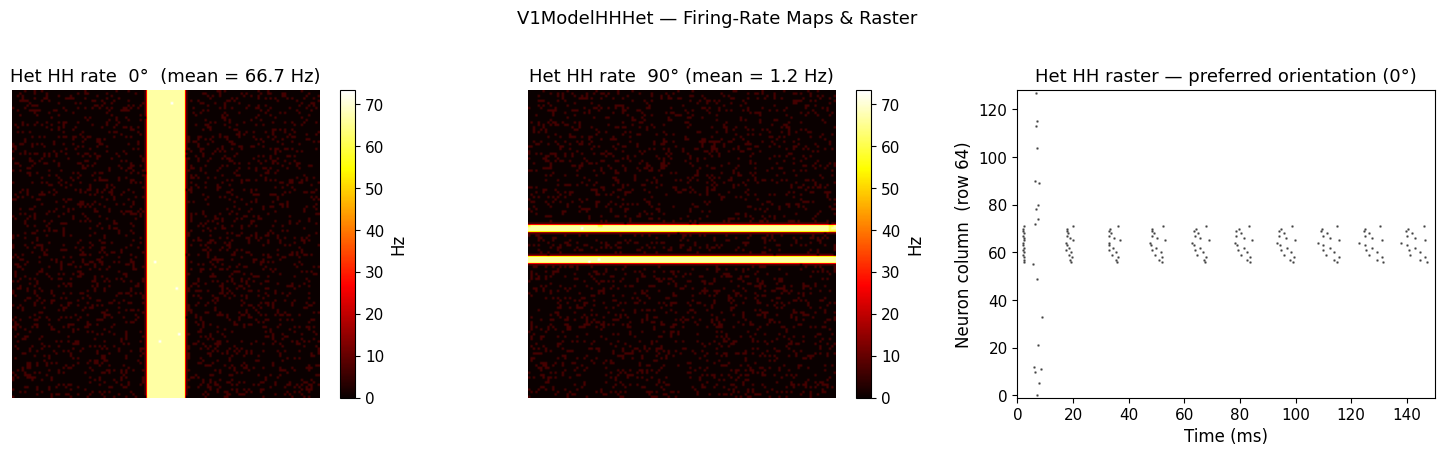

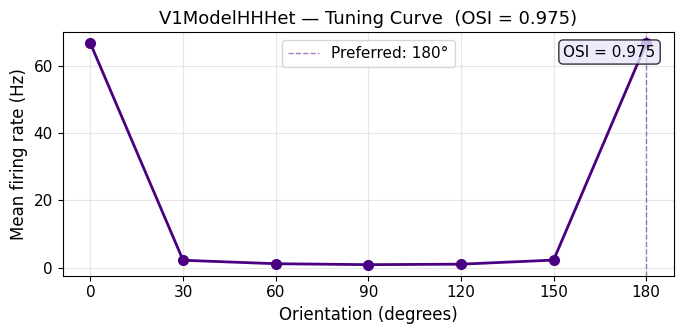


Preferred orientation : 180°
OSI (het HH model)    : 0.9749

   Ori   Rate (Hz)
     0       66.67
    30        2.15
    60        1.13
    90        0.85
   120        0.99
   150        2.21
   180       66.68


In [18]:
class V1ModelHHHet(V1ModelHH):
    """V1ModelHH with static per-neuron input-current gain (heterogeneity)."""

    def forward(self, lgn_layer):
        lgn = lgn_layer.astype(float)
        N   = self.grid_size

        if getattr(self, 'cell_gain', None) is None:
            rng = np.random.default_rng(123)
            self.cell_gain = rng.uniform(*HETEROGENEITY_RANGE, (N, N))

        # Stage 1: MAP orientation field
        sci_map = V1ModelBioVec.forward(self, lgn_layer, self.num_iters_map)

        # Stage 2: heterogeneous drive (µA/cm²)
        I_lgn = (self.I_offset + self.I_scale * sci_map) * self.cell_gain

        V_arr = np.full((N, N), self.V_rest, dtype=float)
        am0, bm0 = self._alpha_m(V_arr), self._beta_m(V_arr)
        ah0, bh0 = self._alpha_h(V_arr), self._beta_h(V_arr)
        an0, bn0 = self._alpha_n(V_arr), self._beta_n(V_arr)
        m_arr = am0 / (am0 + bm0)
        h_arr = ah0 / (ah0 + bh0)
        n_arr = an0 / (an0 + bn0)

        synaptic_trace = np.zeros((N, N), dtype=float)
        spike_count    = np.zeros((N, N), dtype=float)
        syn_decay      = np.exp(-self.dt / self.tau_syn)
        raster         = [[] for _ in range(N)]
        V_prev         = V_arr.copy()
        dt, C_m        = self.dt, self.C_m

        for step in range(self.n_steps):
            t = step * dt
            I_total = I_lgn + self.gamma_lat * synaptic_trace
            if self.noise_sigma > 0:
                I_total = I_total + np.random.normal(0, self.noise_sigma, (N, N))

            I_Na = self.g_Na * m_arr**3 * h_arr * (V_arr - self.E_Na)
            I_K  = self.g_K  * n_arr**4          * (V_arr - self.E_K)
            I_L  = self.g_L                       * (V_arr - self.E_L)

            am = self._alpha_m(V_arr);  bm = self._beta_m(V_arr)
            ah = self._alpha_h(V_arr);  bh = self._beta_h(V_arr)
            an = self._alpha_n(V_arr);  bn = self._beta_n(V_arr)

            V_new = V_arr + (dt / C_m) * (I_total - I_Na - I_K - I_L)
            m_arr = np.clip(m_arr + dt * (am * (1.0 - m_arr) - bm * m_arr), 0.0, 1.0)
            h_arr = np.clip(h_arr + dt * (ah * (1.0 - h_arr) - bh * h_arr), 0.0, 1.0)
            n_arr = np.clip(n_arr + dt * (an * (1.0 - n_arr) - bn * n_arr), 0.0, 1.0)

            spikes = (V_prev < self.spike_threshold) & (V_new >= self.spike_threshold)
            spike_count += spikes
            for c in np.where(spikes[self.raster_row])[0]:
                raster[c].append(t)

            synaptic_trace *= syn_decay
            sp_pad = np.pad(spikes.astype(float), 1, mode='constant', constant_values=0)
            synaptic_trace += (
                sp_pad[1:-1, :-2] + sp_pad[1:-1,  2:]
              + sp_pad[:-2, 1:-1] + sp_pad[2:,  1:-1]
              + sp_pad[:-2, :-2]  + sp_pad[:-2,  2:]
              + sp_pad[2:,  :-2]  + sp_pad[2:,   2:]
            )
            V_prev = V_new
            V_arr  = V_new

        self.last_raster = raster
        return spike_count / self.T_total


np.random.seed(RANDOM_SEED + 40)

model_hh_het = V1ModelHHHet(GRID_SIZE, **HH_PARAMS)

# ── 0° run ────────────────────────────────────────────────────────
stim_0hh   = generate_oriented_bar(GRID_SIZE, orientation_deg=0,  bar_width=BAR_WIDTH)
lgn_0hh    = prepare_lgn_input(stim_0hh, preprocess=True)
rate_hh0h  = model_hh_het.forward(lgn_0hh)
raster_hhh = model_hh_het.last_raster

# ── 90° run ───────────────────────────────────────────────────────
stim_90hh  = generate_oriented_bar(GRID_SIZE, orientation_deg=90, bar_width=BAR_WIDTH)
lgn_90hh   = prepare_lgn_input(stim_90hh, preprocess=True)
rate_hh90h = model_hh_het.forward(lgn_90hh)

R0hh  = rate_hh0h[bar_mask(stim_0hh)].mean()
R90hh = rate_hh90h[bar_mask(stim_90hh)].mean()
print(f"Preferred  (0°):  {R0hh*1000:.1f} Hz")
print(f"Orthogonal (90°): {R90hh*1000:.1f} Hz")

# ── Spread / CV report ─────────────────────────────────────────────
bar_rates_hh   = rate_hh0h[bar_mask(stim_0hh)]
n_distinct_hh  = len(np.unique(np.round(bar_rates_hh, 3)))
assert rate_hh0h.min() >= 0.0
print(f"Firing-rate spread: {n_distinct_hh} distinct rates, std={bar_rates_hh.std():.4f}")
rates_hh_het   = bar_rates_hh[bar_rates_hh > 0] * 1000  # Hz; reused in distribution figure
cv_hh_het      = rates_hh_het.std() / rates_hh_het.mean() if rates_hh_het.mean() > 0 else 0.0
print(f"Active-cell firing rate: mean={rates_hh_het.mean():.1f} Hz, "
      f"std={rates_hh_het.std():.1f} Hz, CV={cv_hh_het:.3f}")

# ── Supplementary maps + raster ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

im0 = axes[0].imshow(rate_hh0h * 1000, cmap='hot', vmin=0)
axes[0].set_title(f'Het HH rate  0°  (mean = {R0hh*1000:.1f} Hz)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], label='Hz')

im1 = axes[1].imshow(rate_hh90h * 1000, cmap='hot', vmin=0)
axes[1].set_title(f'Het HH rate  90° (mean = {R90hh*1000:.1f} Hz)')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], label='Hz')

ax_r = axes[2]
for j, times in enumerate(raster_hhh):
    if times:
        ax_r.scatter(times, [j] * len(times), s=0.8, c='k', alpha=0.5)
ax_r.set_xlabel('Time (ms)')
ax_r.set_ylabel(f'Neuron column  (row {model_hh_het.raster_row})')
ax_r.set_title('Het HH raster — preferred orientation (0°)')
ax_r.set_xlim(0, model_hh_het.T_total)
ax_r.set_ylim(-1, GRID_SIZE)

plt.suptitle('V1ModelHHHet — Firing-Rate Maps & Raster', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_hh_heterogeneity_maps.png', dpi=OUTPUT_DPI, bbox_inches='tight')
plt.show()

# ── Supplementary tuning curve ────────────────────────────────────────
ORIS_HH_H     = list(range(0, 181, 30))
responses_hhh = []

for ori in ORIS_HH_H:
    stim_i = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH)
    lgn_i  = prepare_lgn_input(stim_i, preprocess=True)
    rate_i = model_hh_het.forward(lgn_i)
    responses_hhh.append(rate_i[bar_mask(stim_i)].mean())

responses_hhh = np.array(responses_hhh)
osi_hhh       = compute_osi(responses_hhh, ORIS_HH_H, signed=False)
pref_ori_hhh  = ORIS_HH_H[int(np.argmax(responses_hhh))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ORIS_HH_H, responses_hhh * 1000, 'o-', color='indigo', lw=2, ms=7)
ax.axvline(pref_ori_hhh, color='indigo', lw=1, ls='--', alpha=0.5,
           label=f'Preferred: {pref_ori_hhh}°')
ax.set_xlabel('Orientation (degrees)')
ax.set_ylabel('Mean firing rate (Hz)')
ax.set_title(f'V1ModelHHHet — Tuning Curve  (OSI = {osi_hhh:.3f})')
ax.set_xticks(range(0, 181, 30))
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, f'OSI = {osi_hhh:.3f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.8))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_hh_heterogeneity_tuning.png', dpi=OUTPUT_DPI)
plt.show()

print(f"\nPreferred orientation : {pref_ori_hhh}°")
print(f"OSI (het HH model)    : {osi_hhh:.4f}")
print(f"\n{'Ori':>6}  {'Rate (Hz)':>10}")
for ori, r in zip(ORIS_HH_H, responses_hhh):
    print(f"{ori:6d}  {r*1000:10.2f}")


### Firing-rate distributions and repeated trials

The histograms summarize active-cell firing rates in the preferred-orientation region.
CV describes rate dispersion across cells; it is not a measure of spike-time information.
Ten deterministic noise seeds are used for each model variant so the reported pooled and
per-trial statistics in manuscript Figure 14 can be reproduced exactly.


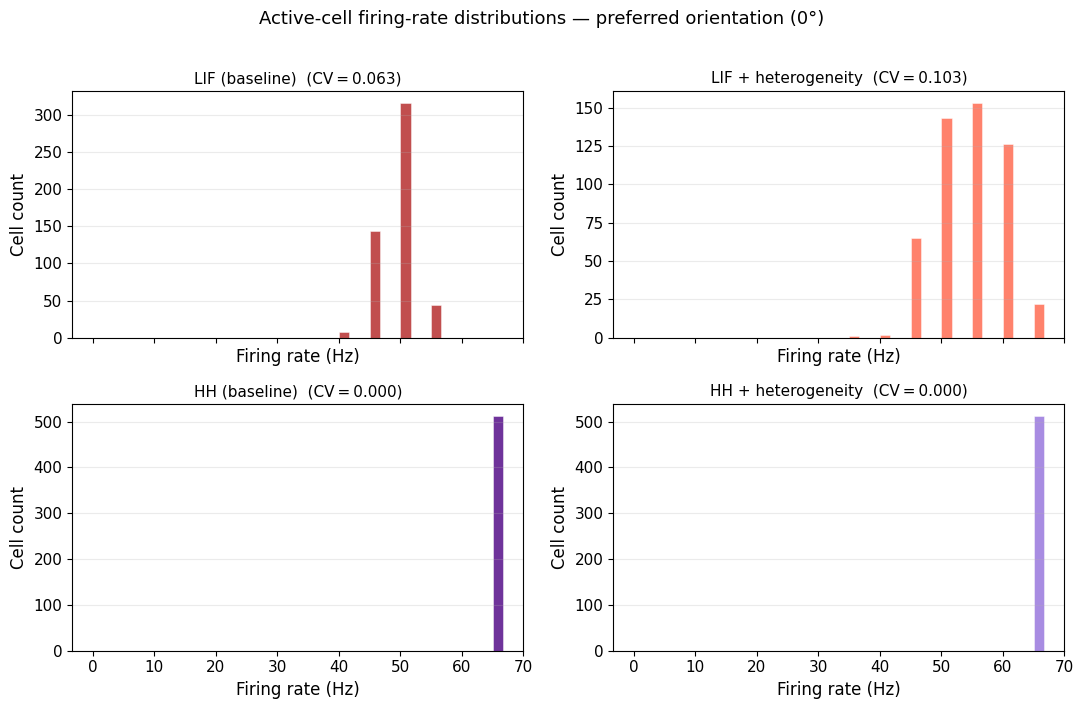

CV summary:
  (CV quantifies across-cell firing-rate dispersion in this run)
  LIF (baseline)          CV = 0.063   - observed dispersion
  LIF + heterogeneity     CV = 0.103   - observed dispersion
  HH  (baseline)          CV = 0.000   - narrow rate distribution
  HH  + heterogeneity     CV = 0.000   - narrow rate distribution


In [19]:
# ── 2×2 histogram grid of active-cell firing-rate distributions ────────────
labels   = ['LIF (baseline)', 'LIF + heterogeneity', 'HH (baseline)', 'HH + heterogeneity']
datasets = [rates_lif, rates_lif_het, rates_hh, rates_hh_het]
colors   = ['firebrick', 'tomato', 'indigo', 'mediumpurple']
cvs      = [cv_lif, cv_lif_het, cv_hh, cv_hh_het]

all_rates = np.concatenate([d for d in datasets if len(d)])
x_max     = float(np.percentile(all_rates, 99)) if len(all_rates) else 200.0

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axes = axes.ravel()

for ax, data, label, color, cv in zip(axes, datasets, labels, colors, cvs):
    if len(data) == 0:
        ax.text(0.5, 0.5, 'No active cells', ha='center', va='center',
                transform=ax.transAxes, fontsize=12)
    else:
        ax.hist(data, bins=40, range=(0, x_max), color=color,
                alpha=0.8, edgecolor='white', linewidth=0.4)
    ax.set_title(f'{label}  (CV = {cv:.3f})', fontsize=11)
    ax.set_xlabel('Firing rate (Hz)')
    ax.set_ylabel('Cell count')
    ax.grid(True, alpha=0.25, axis='y')

plt.suptitle('Active-cell firing-rate distributions — preferred orientation (0°)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_single_trial_rate_distributions.png', dpi=OUTPUT_DPI, bbox_inches='tight')
plt.show()

print("CV summary:")
print("  (CV quantifies across-cell firing-rate dispersion in this run)")
print(f"  LIF (baseline)          CV = {cv_lif:.3f}   - observed dispersion")
print(f"  LIF + heterogeneity     CV = {cv_lif_het:.3f}   - observed dispersion")
print(f"  HH  (baseline)          CV = {cv_hh:.3f}   - narrow rate distribution")
print(f"  HH  + heterogeneity     CV = {cv_hh_het:.3f}   - narrow rate distribution")


In [20]:
# ── Multi-trial repeats: resample stochastic noise to test CV stability ────
# N_TRIALS is declared in the global parameter cell.
mask_0 = bar_mask(stim_0)

def run_trials(model, lgn, mask, seed_base, n_trials=N_TRIALS):
    """Run model.forward() n_trials times with different seeds.
    Returns a list of per-trial active-cell firing-rate arrays (Hz)."""
    trial_rates = []
    for k in range(n_trials):
        np.random.seed(seed_base + k)
        rate_map = model.forward(lgn)
        cell_rates = rate_map[mask] * 1000
        trial_rates.append(cell_rates[cell_rates > 0])
    return trial_rates

print("Running LIF multi-trial sweep...")
trials_lif     = run_trials(model_spk,     lgn_0, mask_0, seed_base=10000)
print("Running LIF+het multi-trial sweep...")
trials_lif_het = run_trials(model_spk_het, lgn_0, mask_0, seed_base=20000)
print("Running HH multi-trial sweep (slow — ~N_TRIALS × the single-run time)...")
trials_hh      = run_trials(model_hh,      lgn_0, mask_0, seed_base=30000)
print("Running HH+het multi-trial sweep...")
trials_hh_het  = run_trials(model_hh_het,  lgn_0, mask_0, seed_base=40000)

def cv(arr):
    return coefficient_of_variation(arr)

print(f"\nPooled CV over {N_TRIALS} trials:")
for name, trials in [('LIF', trials_lif), ('LIF+het', trials_lif_het),
                      ('HH', trials_hh), ('HH+het', trials_hh_het)]:
    pooled = np.concatenate(trials)
    per_trial_cvs = [cv(t) for t in trials]
    print(f"  {name:<10} pooled CV = {cv(pooled):.3f}   "
          f"per-trial CV = {np.mean(per_trial_cvs):.3f} ± {np.std(per_trial_cvs):.3f}")


Running LIF multi-trial sweep...
Running LIF+het multi-trial sweep...
Running HH multi-trial sweep (slow — ~N_TRIALS × the single-run time)...
Running HH+het multi-trial sweep...

Pooled CV over 10 trials:
  LIF        pooled CV = 0.061   per-trial CV = 0.061 ± 0.001
  LIF+het    pooled CV = 0.101   per-trial CV = 0.101 ± 0.001
  HH         pooled CV = 0.000   per-trial CV = 0.000 ± 0.000
  HH+het     pooled CV = 0.005   per-trial CV = 0.004 ± 0.003


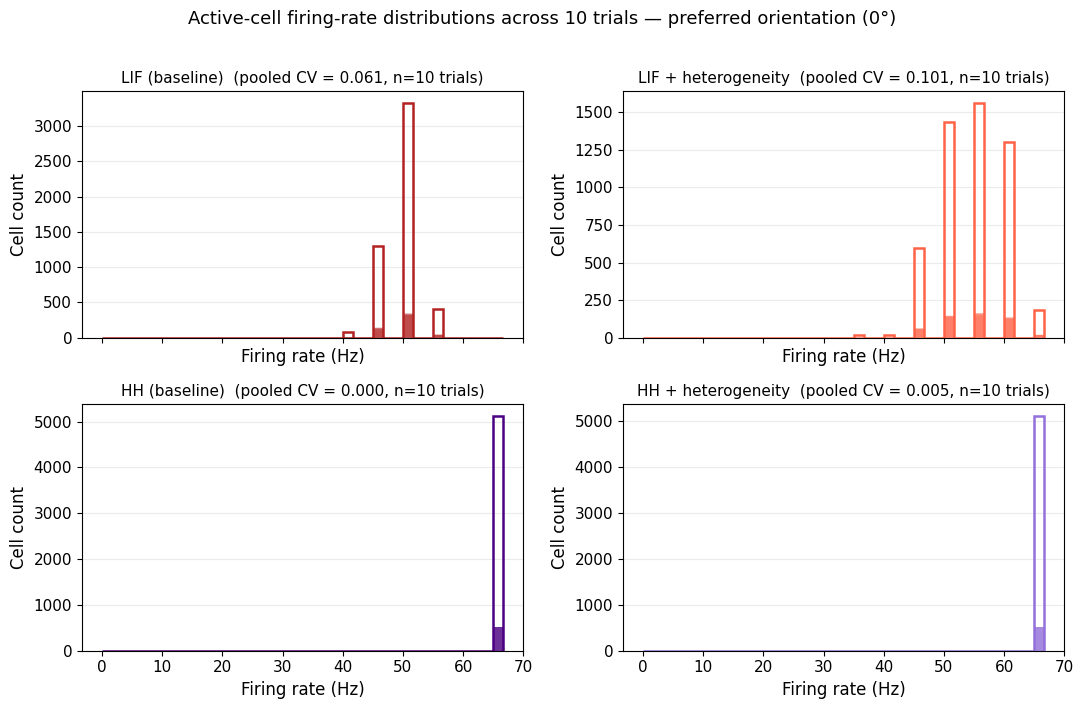

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axes = axes.ravel()

trial_sets = [trials_lif, trials_lif_het, trials_hh, trials_hh_het]
labels     = ['LIF (baseline)', 'LIF + heterogeneity', 'HH (baseline)', 'HH + heterogeneity']
colors     = ['firebrick', 'tomato', 'indigo', 'mediumpurple']

all_rates = np.concatenate([np.concatenate(t) for t in trial_sets if len(t)])
x_max = float(np.percentile(all_rates, 99)) if len(all_rates) else 200.0

for ax, trials, label, color in zip(axes, trial_sets, labels, colors):
    for tr in trials:
        ax.hist(tr, bins=40, range=(0, x_max), color=color, alpha=0.15, edgecolor='none')
    ax.hist(np.concatenate(trials), bins=40, range=(0, x_max),
             histtype='step', color=color, linewidth=1.8)
    ax.set_title(f'{label}  (pooled CV = {cv(np.concatenate(trials)):.3f}, n={N_TRIALS} trials)', fontsize=11)
    ax.set_xlabel('Firing rate (Hz)')
    ax.set_ylabel('Cell count')
    ax.grid(True, alpha=0.25, axis='y')

plt.suptitle(f'Active-cell firing-rate distributions across {N_TRIALS} trials — preferred orientation (0°)',
             fontsize=13, y=1.01)
plt.tight_layout()
save_manuscript_figure(fig, 'figure_14_multitrial_rate_distributions.png')
plt.show()


### Single-neuron frequency-current curves

The $f$–$I$ curves in manuscript Figure 15 characterize how the selected LIF and HH
parameterizations convert constant
input current to spike-count rate. The highlighted gain window explains the rate spread
seen in this simulation. The HH curve is described as relatively flat over the tested
window, not as universal evidence of biological firing-rate bistability.


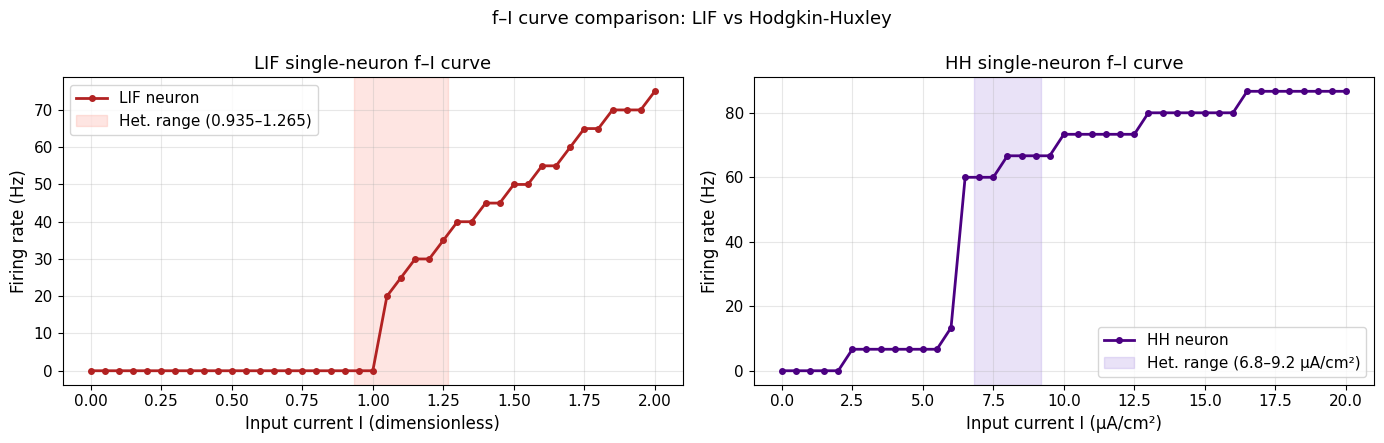

LIF  het. range 0.935–1.265  → rate range 0.0–35.0 Hz  (Δ = 35.0 Hz)
HH   het. range 6.80–9.20 µA/cm²  → rate range 60.0–66.7 Hz  (Δ = 6.7 Hz)


In [22]:
# ── LIF single-neuron f–I sweep ──────────────────────────────────────────────
_lif_dt     = 0.5           # ms
_lif_T      = 200.0         # ms
_lif_nsteps = int(round(_lif_T / _lif_dt))
_lif_tau_m  = 15.0
_lif_Vthr   = 1.0
_lif_Vreset = 0.0
_lif_tref   = max(1, int(round(3.0 / _lif_dt)))   # refractory steps

def lif_single_fr(I_ext):
    """Firing rate (Hz) of a single LIF neuron receiving constant current I_ext."""
    v, ref, spikes = 0.0, 0, 0
    for _ in range(_lif_nsteps):
        if ref > 0:
            v = _lif_Vreset
            ref -= 1
        else:
            v += (_lif_dt / _lif_tau_m) * (-v + I_ext)
            if v >= _lif_Vthr:
                spikes += 1
                v   = _lif_Vreset
                ref = _lif_tref
    return spikes / (_lif_T * 1e-3)   # Hz

GAIN_TRIALS = np.array([0.85, 0.925, 1.0, 1.075, 1.15])
I_sweep_lif  = np.arange(0, 2.05, 0.05)
fr_trials_lif = np.array([[lif_single_fr(I * g) for I in I_sweep_lif] for g in GAIN_TRIALS])
fr_sweep_lif = fr_trials_lif[2]

# Heterogeneity drive band for preferred LIF cells (sci=+1, gain in [0.85, 1.15])
_lif_I_pref = model_spk.I_offset + model_spk.I_scale   # = 1.10
_lif_het_lo = _lif_I_pref * 0.85
_lif_het_hi = _lif_I_pref * 1.15

# ── Single-cell HH f–I sweep ─────────────────────────────────────────────────
_dt, _T  = 0.05, 150.0          # ms
_nsteps  = int(round(_T / _dt))
_g_Na, _g_K, _g_L = 120.0, 36.0, 0.3
_E_Na, _E_K, _E_L, _V_rest, _C_m = 50.0, -77.0, -54.387, -65.0, 1.0

def _am(v): dv=v+40; return np.where(abs(dv)<1e-7, 1.0, 0.1*dv/(1-np.exp(-dv/10)))
def _bm(v): return 4*np.exp(-(v+65)/18)
def _ah(v): return 0.07*np.exp(-(v+65)/20)
def _bh(v): return 1/(1+np.exp(-(v+35)/10))
def _an(v): dv=v+55; return np.where(abs(dv)<1e-7, 0.1, 0.01*dv/(1-np.exp(-dv/10)))
def _bn(v): return 0.125*np.exp(-(v+65)/80)

def hh_single_fr(I_ext):
    """Firing rate (Hz) of a single HH neuron receiving constant current I_ext."""
    v = float(_V_rest)
    m = float(_am(v)/(_am(v)+_bm(v)))
    h = float(_ah(v)/(_ah(v)+_bh(v)))
    n = float(_an(v)/(_an(v)+_bn(v)))
    spikes, v_prev = 0, v
    for _ in range(_nsteps):
        I_Na = _g_Na*m**3*h*(v-_E_Na); I_K = _g_K*n**4*(v-_E_K); I_L = _g_L*(v-_E_L)
        v_new = v + (_dt/_C_m)*(I_ext - I_Na - I_K - I_L)
        m = float(np.clip(m + _dt*(_am(v)*(1-m) - _bm(v)*m), 0, 1))
        h = float(np.clip(h + _dt*(_ah(v)*(1-h) - _bh(v)*h), 0, 1))
        n = float(np.clip(n + _dt*(_an(v)*(1-n) - _bn(v)*n), 0, 1))
        if v_prev < 0 <= v_new:
            spikes += 1
        v_prev, v = v_new, v_new
    return spikes / (_T * 1e-3)   # Hz

I_sweep      = np.arange(0, 20.5, 0.5)
fr_trials_hh = np.array([[hh_single_fr(I * g) for I in I_sweep] for g in GAIN_TRIALS])
fr_sweep     = fr_trials_hh[2]

# Heterogeneity drive band for preferred HH cells (sci=+1, gain in [0.85, 1.15])
_hh_I_pref = model_hh.I_offset + model_hh.I_scale   # = 8.0
I_het_lo   = _hh_I_pref * 0.85
I_het_hi   = _hh_I_pref * 1.15

# ── Two-panel f–I comparison figure ──────────────────────────────────────────
fig, (ax_lif, ax_hh) = plt.subplots(1, 2, figsize=(14, 4.5))

ax_lif.plot(I_sweep_lif, fr_sweep_lif, 'o-', color='firebrick', lw=2, ms=4, label='LIF neuron')
ax_lif.axvspan(_lif_het_lo, _lif_het_hi, alpha=0.20, color='salmon',
               label=f'Het. range ({_lif_het_lo:.3f}–{_lif_het_hi:.3f})')
ax_lif.set_xlabel('Input current I (dimensionless)')
ax_lif.set_ylabel('Firing rate (Hz)')
ax_lif.set_title('LIF single-neuron f–I curve')
ax_lif.legend(fontsize=11)
ax_lif.grid(True, alpha=0.3)

ax_hh.plot(I_sweep, fr_sweep, 'o-', color='indigo', lw=2, ms=4, label='HH neuron')
ax_hh.axvspan(I_het_lo, I_het_hi, alpha=0.20, color='mediumpurple',
              label=f'Het. range ({I_het_lo:.1f}–{I_het_hi:.1f} µA/cm²)')
ax_hh.set_xlabel('Input current I (µA/cm²)')
ax_hh.set_ylabel('Firing rate (Hz)')
ax_hh.set_title('HH single-neuron f–I curve')
ax_hh.legend(fontsize=11)
ax_hh.grid(True, alpha=0.3)

plt.suptitle('f–I curve comparison: LIF vs Hodgkin-Huxley', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'supplementary_fi_reference_curves.png', dpi=OUTPUT_DPI)
plt.show()

# ── Summary ──────────────────────────────────────────────────────────────────
_lif_win = fr_sweep_lif[(I_sweep_lif >= _lif_het_lo) & (I_sweep_lif <= _lif_het_hi)]
_hh_win  = fr_sweep    [(I_sweep     >= I_het_lo)    & (I_sweep     <= I_het_hi)]
print(f"LIF  het. range {_lif_het_lo:.3f}–{_lif_het_hi:.3f}  "
      f"→ rate range {_lif_win.min() if len(_lif_win) else 0:.1f}–"
      f"{_lif_win.max() if len(_lif_win) else 0:.1f} Hz  "
      f"(Δ = {(_lif_win.max()-_lif_win.min()) if len(_lif_win) else 0:.1f} Hz)")
print(f"HH   het. range {I_het_lo:.2f}–{I_het_hi:.2f} µA/cm²  "
      f"→ rate range {_hh_win.min() if len(_hh_win) else 0:.1f}–"
      f"{_hh_win.max() if len(_hh_win) else 0:.1f} Hz  "
      f"(Δ = {(_hh_win.max()-_hh_win.min()) if len(_hh_win) else 0:.1f} Hz)")


Running LIF noise sweep (6 runs)...
Running HH noise sweep (6 runs — may take ~1–2 min)...


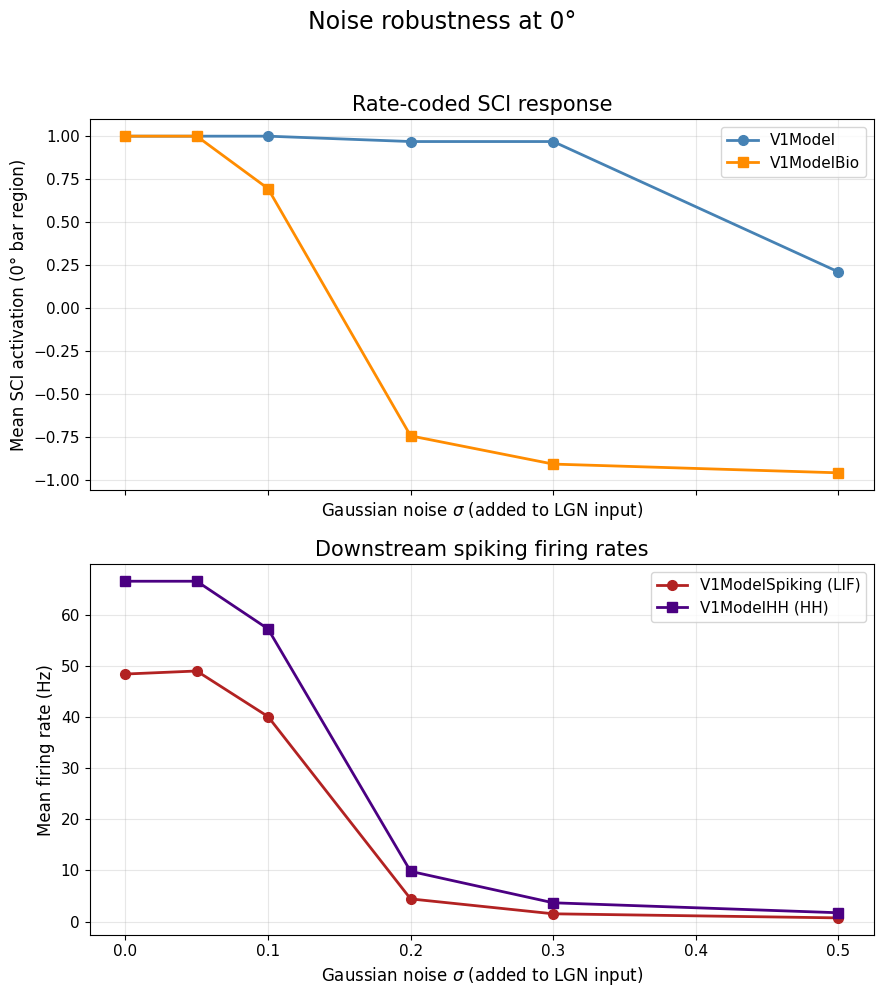


 Sigma    V1Model      V1Bio    LIF(Hz)     HH(Hz)
----------------------------------------------------------
  0.00     1.0000     1.0000       48.5       66.7
  0.05     1.0000     1.0000       49.1       66.7
  0.10     1.0000     0.6953       40.2       57.3
  0.20     0.9688    -0.7422        4.4        9.8
  0.30     0.9688    -0.9062        1.5        3.7
  0.50     0.2109    -0.9570        0.7        1.7
Running LIF noise sweep (6 runs)...
Running HH noise sweep (6 runs — may take ~1–2 min)...


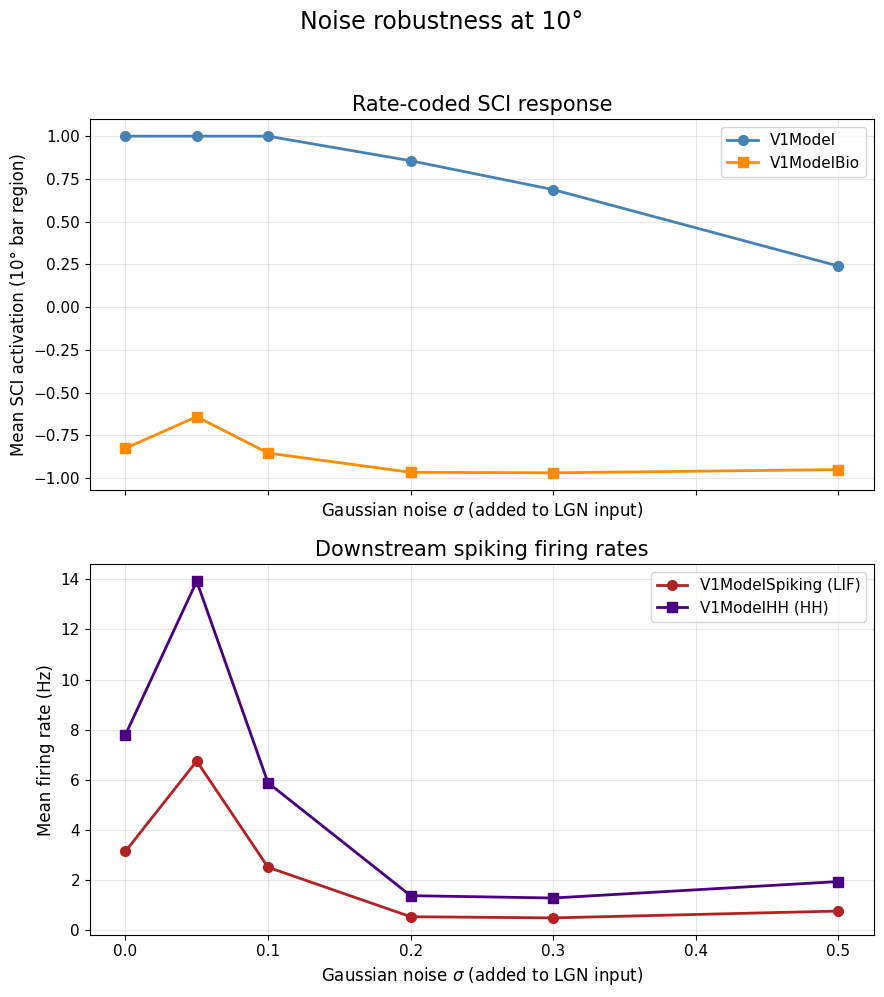


 Sigma    V1Model      V1Bio    LIF(Hz)     HH(Hz)
----------------------------------------------------------
  0.00     1.0000    -0.8250        3.1        7.8
  0.05     1.0000    -0.6406        6.7       13.9
  0.10     1.0000    -0.8531        2.5        5.9
  0.20     0.8562    -0.9656        0.5        1.4
  0.30     0.6875    -0.9688        0.5        1.3
  0.50     0.2406    -0.9500        0.8        1.9
Running LIF noise sweep (6 runs)...
Running HH noise sweep (6 runs — may take ~1–2 min)...


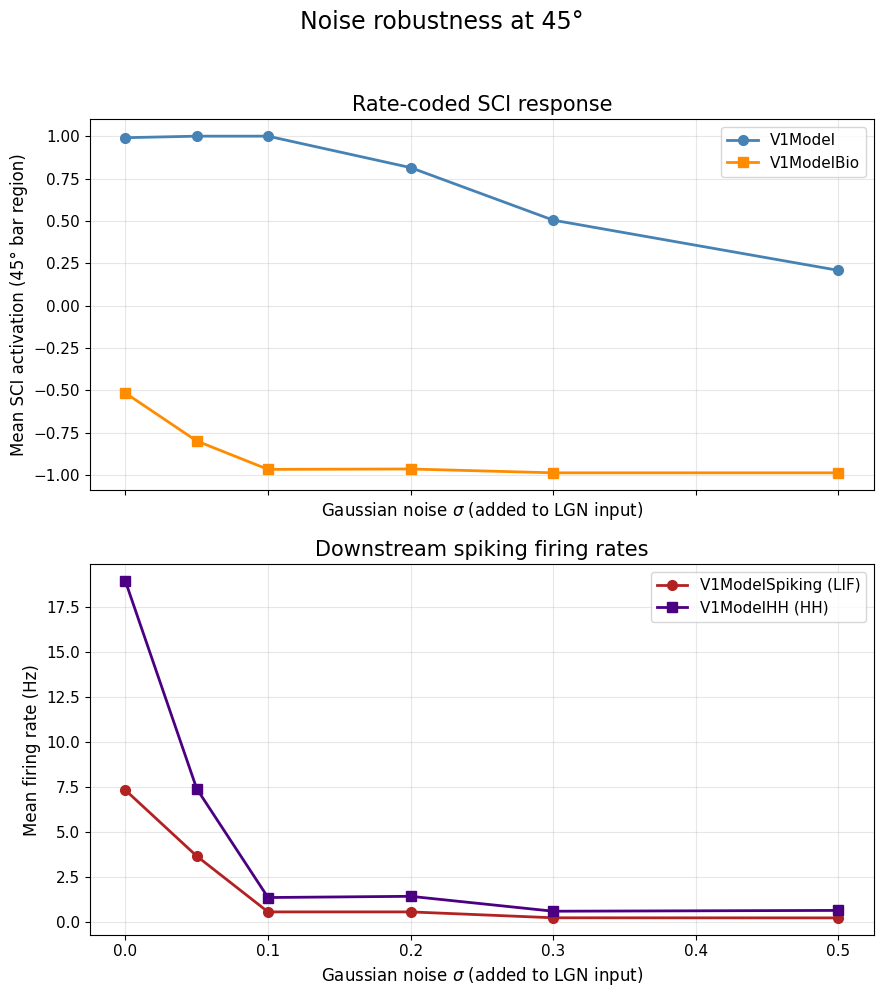


 Sigma    V1Model      V1Bio    LIF(Hz)     HH(Hz)
----------------------------------------------------------
  0.00     0.9910    -0.5158        7.3       18.9
  0.05     1.0000    -0.7986        3.6        7.4
  0.10     1.0000    -0.9661        0.5        1.3
  0.20     0.8145    -0.9638        0.5        1.4
  0.30     0.5045    -0.9864        0.2        0.6
  0.50     0.2081    -0.9864        0.2        0.6
Running LIF noise sweep (6 runs)...
Running HH noise sweep (6 runs — may take ~1–2 min)...


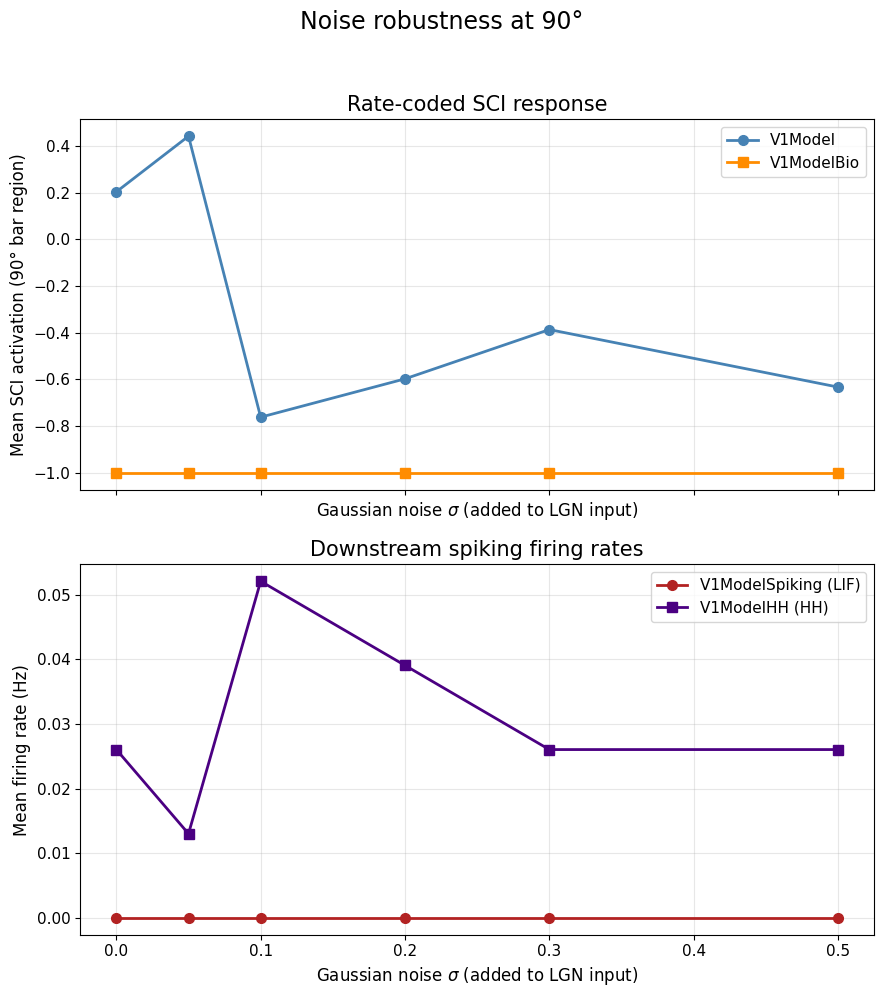


 Sigma    V1Model      V1Bio    LIF(Hz)     HH(Hz)
----------------------------------------------------------
  0.00     0.2031    -1.0000        0.0        0.0
  0.05     0.4414    -1.0000        0.0        0.0
  0.10    -0.7617    -1.0000        0.0        0.1
  0.20    -0.5977    -1.0000        0.0        0.0
  0.30    -0.3867    -1.0000        0.0        0.0
  0.50    -0.6328    -1.0000        0.0        0.0


In [23]:
np.random.seed(RANDOM_SEED + 50)
BAR_ORIS_B = NOISE_ORIENTATIONS
for BAR_ORI_B in BAR_ORIS_B:
    stim_b0      = generate_oriented_bar(GRID_SIZE, orientation_deg=BAR_ORI_B, bar_width=BAR_WIDTH,
                                        contrast=1.0, background_intensity=0.5)
    lgn_b0_clean = prepare_lgn_input(stim_b0, preprocess=True)
    mask_b0      = bar_mask(stim_b0)

    # Pre-generate identical noise arrays for all models at each sigma level
    _rng_noise = np.random.RandomState(RANDOM_SEED + 500 + BAR_ORI_B)
    lgn_noisy = []
    for _s in NOISE_LEVELS:
        _n = _rng_noise.normal(0, _s, lgn_b0_clean.shape) if _s > 0 else np.zeros_like(lgn_b0_clean)
        lgn_noisy.append(np.clip(lgn_b0_clean + _n, 0, 1))

    # ── Rate models ──────────────────────────────────────────────────────────────
    model_v_b   = V1ModelVec(GRID_SIZE, BETA, GAMMA, T)
    model_bio_b = V1ModelBioVec(GRID_SIZE, BETA, GAMMA, T)

    mean_v_b, mean_bio_b = [], []
    for lgn_n in lgn_noisy:
        mean_v_b.append(model_v_b.forward(lgn_n, NUM_ITERS)[mask_b0].mean())
        mean_bio_b.append(model_bio_b.forward(lgn_n, NUM_ITERS)[mask_b0].mean())

    # ── Spiking models (reuse model_spk / model_hh from earlier cells) ───────────
    print("Running LIF noise sweep (6 runs)...")
    mean_lif_b = []
    for i, lgn_n in enumerate(lgn_noisy):
        np.random.seed(RANDOM_SEED + 1000 + 100 * BAR_ORI_B + i)
        rate_n = model_spk.forward(lgn_n)
        mean_lif_b.append(rate_n[mask_b0].mean() * 1000)   # Hz

    print("Running HH noise sweep (6 runs — may take ~1–2 min)...")
    mean_hh_b = []
    for i, lgn_n in enumerate(lgn_noisy):
        np.random.seed(RANDOM_SEED + 2000 + 100 * BAR_ORI_B + i)
        rate_n = model_hh.forward(lgn_n)
        mean_hh_b.append(rate_n[mask_b0].mean() * 1000)    # Hz

    # ── Readable two-panel manuscript figure ───────────────────────────────────────
    fig, (ax_rate, ax_spk) = plt.subplots(2, 1, figsize=(9, 10), sharex=True)

    ax_rate.plot(NOISE_LEVELS, mean_v_b,   'o-', color='steelblue',   lw=2, ms=7, label='V1Model')
    ax_rate.plot(NOISE_LEVELS, mean_bio_b, 's-', color='darkorange',  lw=2, ms=7, label='V1ModelBio')
    ax_rate.set_xlabel(r'Gaussian noise $\sigma$ (added to LGN input)')
    ax_rate.set_ylabel(f'Mean SCI activation ({BAR_ORI_B}° bar region)')
    ax_rate.set_title('Rate-coded SCI response', fontsize=15)
    ax_rate.legend(fontsize=11)
    ax_rate.grid(True, alpha=0.3)

    ax_spk.plot(NOISE_LEVELS, mean_lif_b, 'o-', color='firebrick', lw=2, ms=7, label='V1ModelSpiking (LIF)')
    ax_spk.plot(NOISE_LEVELS, mean_hh_b,  's-', color='indigo',    lw=2, ms=7, label='V1ModelHH (HH)')
    ax_spk.set_xlabel(r'Gaussian noise $\sigma$ (added to LGN input)')
    ax_spk.set_ylabel('Mean firing rate (Hz)')
    ax_spk.set_title('Downstream spiking firing rates', fontsize=15)
    ax_spk.legend(fontsize=11)
    ax_spk.grid(True, alpha=0.3)

    fig.suptitle(f'Noise robustness at {BAR_ORI_B}°', fontsize=17, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    figure_number = {0: 6, 10: 7, 45: 8, 90: 9}[BAR_ORI_B]
    save_manuscript_figure(
        fig, f'figure_{figure_number:02d}_noise_robustness_{BAR_ORI_B}deg.png'
    )
    plt.show()

    print(f'\n{"Sigma":>6}  {"V1Model":>9}  {"V1Bio":>9}  {"LIF(Hz)":>9}  {"HH(Hz)":>9}')
    print('-' * 58)
    for i, s in enumerate(NOISE_LEVELS):
        print(f'{s:6.2f}  {mean_v_b[i]:9.4f}  {mean_bio_b[i]:9.4f}  '
            f'{mean_lif_b[i]:9.1f}  {mean_hh_b[i]:9.1f}')


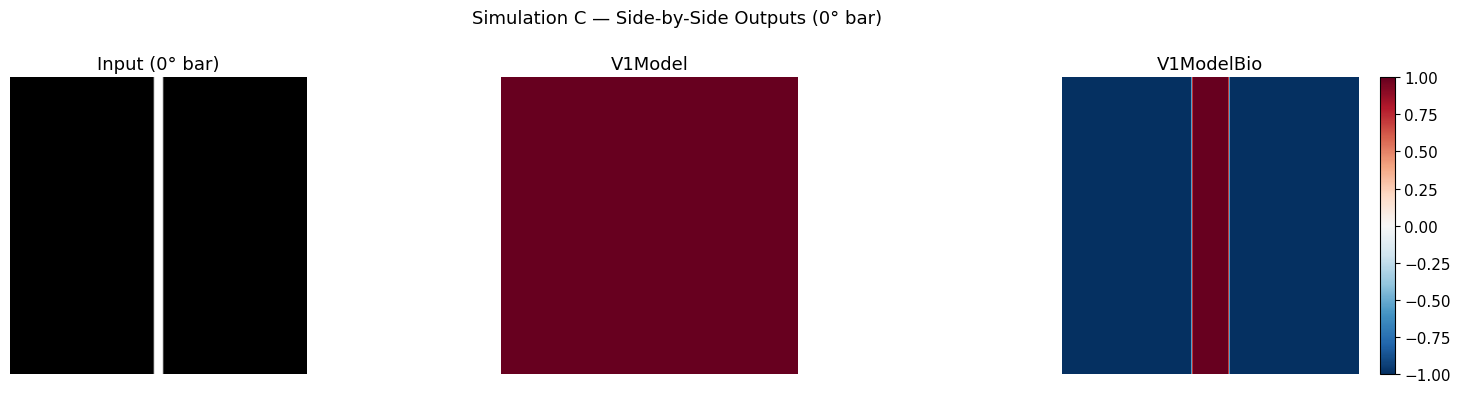

Rate-model tuning sweep...
LIF tuning sweep (19 orientations)...
HH tuning sweep (19 orientations — may take ~2–3 min)...


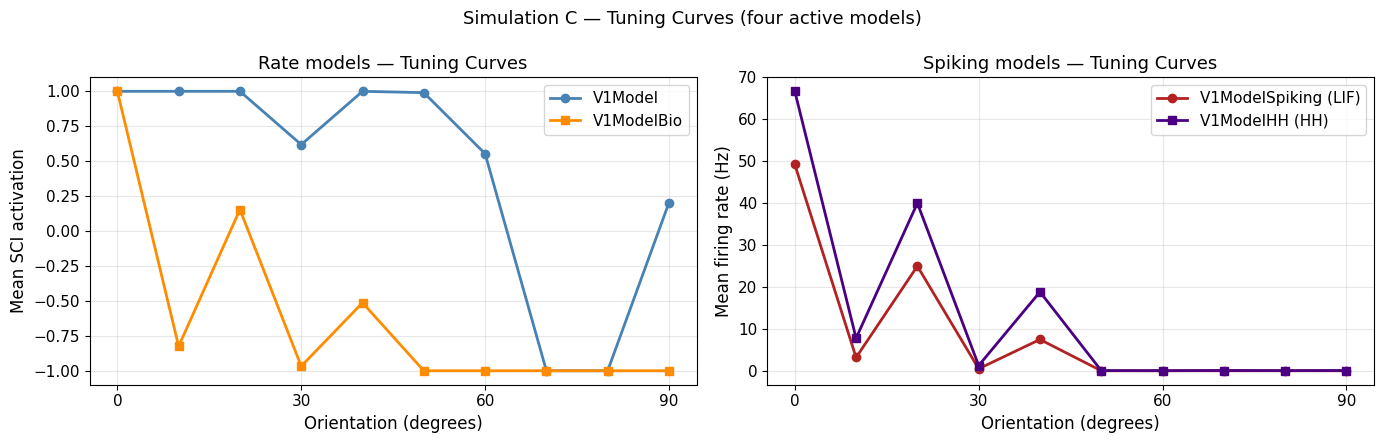


Model                            OSI   Preferred
--------------------------------------------------
V1Model                       0.2488           0°
V1ModelBio                    1.0000           0°
V1ModelSpiking                1.0000         180°
V1ModelHH                     0.9984           0°


In [24]:
# --- shared input (0° bar) ---
stim_c = generate_oriented_bar(GRID_SIZE, orientation_deg=0, bar_width=BAR_WIDTH,
                                contrast=1.0, background_intensity=0.5)
lgn_c  = prepare_lgn_input(stim_c, preprocess=True)

model_v_c   = V1ModelVec(GRID_SIZE, BETA, GAMMA, T)
model_bio_c = V1ModelBioVec(GRID_SIZE, BETA, GAMMA, T)

sci_v_c   = model_v_c.forward(lgn_c, NUM_ITERS)
sci_bio_c = model_bio_c.forward(lgn_c, NUM_ITERS)

# --- side-by-side outputs (rate models) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(stim_c, cmap='gray');               axes[0].set_title('Input (0° bar)')
axes[1].imshow(sci_v_c,   cmap='RdBu_r', vmin=-1, vmax=1); axes[1].set_title('V1Model')
im = axes[2].imshow(sci_bio_c, cmap='RdBu_r', vmin=-1, vmax=1); axes[2].set_title('V1ModelBio')
for ax in axes: ax.axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.suptitle('Simulation C — Side-by-Side Outputs (0° bar)', fontsize=13)
plt.tight_layout()
save_manuscript_figure(fig, 'figure_10_rate_model_outputs.png')
plt.show()

# --- tuning curves: rate models ---
resp_v_c, resp_bio_c = [], []
resp_lif_c, resp_hh_c = [], []

print("Rate-model tuning sweep...")
for ori in ORIENTATIONS:
    stim_ori = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH,
                                     contrast=1.0, background_intensity=0.5)
    lgn_ori  = prepare_lgn_input(stim_ori, preprocess=True)
    m        = bar_mask(stim_ori)
    resp_v_c.append(model_v_c.forward(lgn_ori, NUM_ITERS)[m].mean())
    resp_bio_c.append(model_bio_c.forward(lgn_ori, NUM_ITERS)[m].mean())

print("LIF tuning sweep (19 orientations)...")
np.random.seed(1)
for ori in ORIENTATIONS:
    stim_ori = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH,
                                     contrast=1.0, background_intensity=0.5)
    lgn_ori  = prepare_lgn_input(stim_ori, preprocess=True)
    m        = bar_mask(stim_ori)
    resp_lif_c.append(model_spk.forward(lgn_ori)[m].mean() * 1000)   # Hz

print("HH tuning sweep (19 orientations — may take ~2–3 min)...")
np.random.seed(2)
for ori in ORIENTATIONS:
    stim_ori = generate_oriented_bar(GRID_SIZE, orientation_deg=ori, bar_width=BAR_WIDTH,
                                     contrast=1.0, background_intensity=0.5)
    lgn_ori  = prepare_lgn_input(stim_ori, preprocess=True)
    m        = bar_mask(stim_ori)
    resp_hh_c.append(model_hh.forward(lgn_ori)[m].mean() * 1000)    # Hz

resp_v_c   = np.array(resp_v_c)
resp_bio_c = np.array(resp_bio_c)
resp_lif_c = np.array(resp_lif_c)
resp_hh_c  = np.array(resp_hh_c)

# --- OSI for four active models ---
osi_v_c   = compute_osi(resp_v_c,   ORIENTATIONS)
osi_bio_c = compute_osi(resp_bio_c, ORIENTATIONS)
osi_lif_c = compute_osi(resp_lif_c, ORIENTATIONS, signed=False)
osi_hh_c  = compute_osi(resp_hh_c,  ORIENTATIONS, signed=False)

plot_oris = np.array(ORIENTATIONS)
plot_mask = plot_oris <= 90
plot_oris = plot_oris[plot_mask]

# --- Two-panel tuning figure ---
fig, (ax_rate, ax_spk) = plt.subplots(1, 2, figsize=(14, 4.5))

ax_rate.plot(plot_oris, resp_v_c[plot_mask],   'o-', label='V1Model',          color='steelblue',   lw=2)
ax_rate.plot(plot_oris, resp_bio_c[plot_mask], 's-', label='V1ModelBio',       color='darkorange',  lw=2)
ax_rate.set_xlabel('Orientation (degrees)')
ax_rate.set_ylabel('Mean SCI activation')
ax_rate.set_title('Rate models — Tuning Curves')
ax_rate.set_xticks(range(0, 91, 30))
ax_rate.legend(fontsize=11)
ax_rate.grid(True, alpha=0.3)

ax_spk.plot(plot_oris, resp_lif_c[plot_mask], 'o-', label='V1ModelSpiking (LIF)', color='firebrick', lw=2)
ax_spk.plot(plot_oris, resp_hh_c[plot_mask],  's-', label='V1ModelHH (HH)',       color='indigo',    lw=2)
ax_spk.set_xlabel('Orientation (degrees)')
ax_spk.set_ylabel('Mean firing rate (Hz)')
ax_spk.set_title('Spiking models — Tuning Curves')
ax_spk.set_xticks(range(0, 91, 30))
ax_spk.legend(fontsize=11)
ax_spk.grid(True, alpha=0.3)

plt.suptitle('Simulation C — Tuning Curves (four active models)', fontsize=13)
plt.tight_layout()
save_manuscript_figure(fig, 'figure_11_model_tuning_curves.png')
plt.show()

# --- OSI summary table ---
print(f'\n{"Model":<26}  {"OSI":>8}  {"Preferred":>10}')
print('-' * 50)
for name, resp, osi, signed in [
    ('V1Model',          resp_v_c,   osi_v_c,   True),
    ('V1ModelBio',       resp_bio_c, osi_bio_c, True),
    ('V1ModelSpiking',   resp_lif_c, osi_lif_c, False),
    ('V1ModelHH',        resp_hh_c,  osi_hh_c,  False),
]:
    _pref = ORIENTATIONS[int(np.argmax(resp if not signed else (resp+1)/2))]
    print(f'{name:<26}  {osi:8.4f}  {_pref:>10}°')


In [25]:
if not GENERATE_SUPPLEMENTARY_PANELS:
    print('Supplementary per-trial panels skipped (set GENERATE_SUPPLEMENTARY_PANELS=True to create).')
else:
    N_SHOW = 4   # individual trial panels shown per model (paper-style small multiples)

    def plot_trial_panel(trials, label, color, n_show=N_SHOW):
        x_max = float(np.percentile(np.concatenate(trials), 99))
        fig, axes = plt.subplots(1, n_show, figsize=(3*(n_show), 3), sharey=True)

        for i in range(n_show):
            axes[i].hist(trials[i], bins=30, range=(0, x_max), color=color,
                          alpha=0.85, edgecolor='white', linewidth=0.3)
            axes[i].set_title(f'Trial {i+1}\nCV={cv(trials[i]):.3f}', fontsize=9)
            axes[i].set_xlabel('Rate (Hz)')
        axes[0].set_ylabel('Cell count')

        # ax_ov = axes[-1]
        # for tr in trials:
        #     ax_ov.hist(tr, bins=30, range=(0, x_max), color=color, alpha=0.12, edgecolor='none')
        # pooled = np.concatenate(trials)
        # ax_ov.hist(pooled, bins=30, range=(0, x_max), histtype='step', color='black', linewidth=1.8)
        # ax_ov.set_title(f'Overlay (n={len(trials)})\nPooled CV={cv(pooled):.3f}', fontsize=9)
        # ax_ov.set_xlabel('Rate (Hz)')

        plt.suptitle(label, fontsize=12, y=1.05)
        plt.tight_layout()
        fname = 'trial_panels_' + label.lower().replace(' ', '_').replace('+', '').replace('(', '').replace(')', '') + '.png'
        plt.savefig(FIGURE_DIR / fname, dpi=OUTPUT_DPI, bbox_inches='tight')
        plt.show()

    for trials, label, color in zip(trial_sets, labels, colors):
        plot_trial_panel(trials, label, color)


Supplementary per-trial panels skipped (set GENERATE_SUPPLEMENTARY_PANELS=True to create).


In [26]:
if not GENERATE_SUPPLEMENTARY_PANELS:
    print('Supplementary gain panels skipped (set GENERATE_SUPPLEMENTARY_PANELS=True to create).')
else:
    def plot_fI_panel(I_sweep, fr_trials, gains, label, color):
        n = len(gains)
        fig, axes = plt.subplots(1, n + 1, figsize=(3*(n+1), 3), sharey=True)
        for i, g in enumerate(gains):
            axes[i].plot(I_sweep, fr_trials[i], color=color, lw=1.5)
            axes[i].set_title(f'gain={g:.3f}', fontsize=9)
            axes[i].set_xlabel('I')
        axes[0].set_ylabel('Firing rate (Hz)')

        ax_ov = axes[-1]
        for tr in fr_trials:
            ax_ov.plot(I_sweep, tr, color=color, alpha=0.4, lw=1.2)
        ax_ov.set_title(f'Overlay (n={n} gains)', fontsize=9)
        ax_ov.set_xlabel('I')

        plt.suptitle(label, fontsize=12, y=1.05)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / f'fI_gain_panels_{label.lower()}.png', dpi=OUTPUT_DPI, bbox_inches='tight')
        plt.show()

    plot_fI_panel(I_sweep_lif, fr_trials_lif, GAIN_TRIALS, 'LIF f-I curve', 'firebrick')
    plot_fI_panel(I_sweep,     fr_trials_hh,  GAIN_TRIALS, 'HH f-I curve',  'indigo')


Supplementary gain panels skipped (set GENERATE_SUPPLEMENTARY_PANELS=True to create).


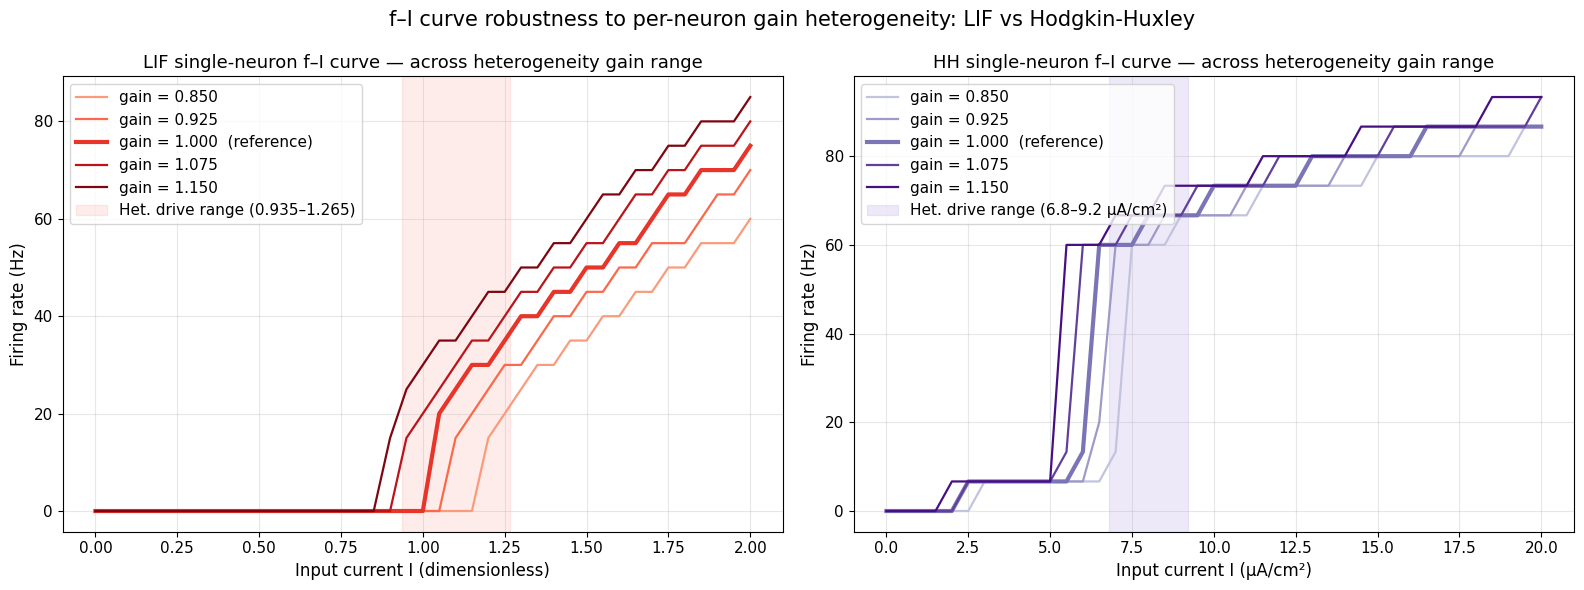

In [27]:
# ── Publication figure: f–I curves across the full heterogeneity gain range ──
fig, (ax_lif, ax_hh) = plt.subplots(1, 2, figsize=(16, 6))

gain_cmap = plt.cm.Reds(np.linspace(0.35, 0.95, len(GAIN_TRIALS)))
gain_cmap_hh = plt.cm.Purples(np.linspace(0.35, 0.95, len(GAIN_TRIALS)))

for g, fr, c in zip(GAIN_TRIALS, fr_trials_lif, gain_cmap):
    lw = 3 if np.isclose(g, 1.0) else 1.6
    ax_lif.plot(I_sweep_lif, fr, '-', color=c, lw=lw,
                label=f'gain = {g:.3f}' + ('  (reference)' if np.isclose(g, 1.0) else ''))
ax_lif.axvspan(_lif_het_lo, _lif_het_hi, alpha=0.15, color='salmon',
               label=f'Het. drive range ({_lif_het_lo:.3f}–{_lif_het_hi:.3f})')
ax_lif.set_xlabel('Input current I (dimensionless)', fontsize=12)
ax_lif.set_ylabel('Firing rate (Hz)', fontsize=12)
ax_lif.set_title('LIF single-neuron f–I curve — across heterogeneity gain range', fontsize=13)
ax_lif.legend(fontsize=11, loc='upper left')
ax_lif.grid(True, alpha=0.3)
ax_lif.tick_params(labelsize=11)

for g, fr, c in zip(GAIN_TRIALS, fr_trials_hh, gain_cmap_hh):
    lw = 3 if np.isclose(g, 1.0) else 1.6
    ax_hh.plot(I_sweep, fr, '-', color=c, lw=lw,
               label=f'gain = {g:.3f}' + ('  (reference)' if np.isclose(g, 1.0) else ''))
ax_hh.axvspan(I_het_lo, I_het_hi, alpha=0.15, color='mediumpurple',
              label=f'Het. drive range ({I_het_lo:.1f}–{I_het_hi:.1f} µA/cm²)')
ax_hh.set_xlabel('Input current I (µA/cm²)', fontsize=12)
ax_hh.set_ylabel('Firing rate (Hz)', fontsize=12)
ax_hh.set_title('HH single-neuron f–I curve — across heterogeneity gain range', fontsize=13)
ax_hh.legend(fontsize=11, loc='upper left')
ax_hh.grid(True, alpha=0.3)
ax_hh.tick_params(labelsize=11)

plt.suptitle('f–I curve robustness to per-neuron gain heterogeneity: LIF vs Hodgkin-Huxley', fontsize=15)
plt.tight_layout()
save_manuscript_figure(fig, 'figure_15_fi_curves.png')
plt.show()


In [28]:
# Code-generated manuscript figure manifest. Figure 1 is author-created and intentionally absent.
MANUSCRIPT_FIGURES = {
    2: "figure_02_runtime_memory_benchmark.png",
    3: "figure_03_qualitative_orientation_response.png",
    4: "figure_04_orientation_tuning_curve.png",
    5: "figure_05_normalized_input_contrast.png",
    6: "figure_06_noise_robustness_0deg.png",
    7: "figure_07_noise_robustness_10deg.png",
    8: "figure_08_noise_robustness_45deg.png",
    9: "figure_09_noise_robustness_90deg.png",
    10: "figure_10_rate_model_outputs.png",
    11: "figure_11_model_tuning_curves.png",
    12: "figure_12_hh_spiking_readout.png",
    13: "figure_13_lif_spiking_readout.png",
    14: "figure_14_multitrial_rate_distributions.png",
    15: "figure_15_fi_curves.png",
}

for figure_number, filename in MANUSCRIPT_FIGURES.items():
    generated_path = FIGURE_DIR / filename
    manuscript_path = MANUSCRIPT_FIGURE_DIR / filename
    for label, path in (("generated", generated_path), ("tracked", manuscript_path)):
        if not path.exists() or path.stat().st_size == 0:
            raise FileNotFoundError(
                f"Missing {label} copy of manuscript Figure {figure_number}: {path}"
            )
    print(
        f"Figure {figure_number:>2}: {filename:<52} "
        f"{manuscript_path.stat().st_size / 1024:8.1f} KiB"
    )


Figure  2: figure_02_runtime_memory_benchmark.png                  332.2 KiB
Figure  3: figure_03_qualitative_orientation_response.png          426.4 KiB
Figure  4: figure_04_orientation_tuning_curve.png                  185.4 KiB
Figure  5: figure_05_normalized_input_contrast.png                 325.5 KiB
Figure  6: figure_06_noise_robustness_0deg.png                     334.1 KiB
Figure  7: figure_07_noise_robustness_10deg.png                    327.5 KiB
Figure  8: figure_08_noise_robustness_45deg.png                    309.9 KiB
Figure  9: figure_09_noise_robustness_90deg.png                    312.4 KiB
Figure 10: figure_10_rate_model_outputs.png                         89.1 KiB
Figure 11: figure_11_model_tuning_curves.png                       320.9 KiB
Figure 12: figure_12_hh_spiking_readout.png                        200.6 KiB
Figure 13: figure_13_lif_spiking_readout.png                       197.9 KiB
Figure 14: figure_14_multitrial_rate_distributions.png             228.2 KiB

In [29]:
# Firing-rate sanity checks for the four spiking variants.
for name, data in [
    ("LIF baseline", rates_lif),
    ("LIF + heterogeneity", rates_lif_het),
    ("HH baseline", rates_hh),
    ("HH + heterogeneity", rates_hh_het),
]:
    data = np.asarray(data)
    assert np.all(np.isfinite(data))
    assert np.all(data >= 0)
    print(
        f"{name:<24} n={len(data):5d}  max={data.max():7.1f} Hz  "
        f"p99={np.percentile(data, 99):7.1f} Hz  n>100Hz={np.sum(data > 100):4d}"
    )


LIF baseline             n=  512  max=   55.0 Hz  p99=   55.0 Hz  n>100Hz=   0
LIF + heterogeneity      n=  512  max=   65.0 Hz  p99=   65.0 Hz  n>100Hz=   0
HH baseline              n=  512  max=   66.7 Hz  p99=   66.7 Hz  n>100Hz=   0
HH + heterogeneity       n=  512  max=   66.7 Hz  p99=   66.7 Hz  n>100Hz=   0


In [30]:
# Correct OSI summary using the manuscript's preferred-versus-orthogonal definition.
# Signed rate-model fields are remapped from [-1, 1] to [0, 1]; firing rates are already non-negative.
osi_summary = [
    ("V1Model", compute_osi(resp_v_c, ORIENTATIONS, signed=True)),
    ("V1ModelBio", compute_osi(resp_bio_c, ORIENTATIONS, signed=True)),
    ("LIF readout", compute_osi(resp_lif_c, ORIENTATIONS, signed=False)),
    ("HH readout", compute_osi(resp_hh_c, ORIENTATIONS, signed=False)),
    ("LIF + heterogeneity", compute_osi(responses_spkh, ORIS_SPK_H, signed=False)),
    ("HH + heterogeneity", compute_osi(responses_hhh, ORIS_HH_H, signed=False)),
]

print("Two-point orientation selectivity index")
print("-" * 48)
for name, value in osi_summary:
    assert 0.0 <= value <= 1.0, f"OSI outside [0, 1] for {name}: {value}"
    print(f"{name:<28} {value:8.4f}")


Two-point orientation selectivity index
------------------------------------------------
V1Model                        0.2488
V1ModelBio                     1.0000
LIF readout                    1.0000
HH readout                     0.9984
LIF + heterogeneity            1.0000
HH + heterogeneity             0.9749


In [31]:
# Final reproducibility checks.
assert GRID_SIZE == 128
assert N_NEURONS == 16_384
assert len(NOISE_ORIENTATIONS) == 4
assert set(NOISE_ORIENTATIONS) == {0, 10, 45, 90}
assert RECURRENCE_CHECK_PASSED
assert BENCHMARK_SIZES == (16, 64, 128)
assert BENCHMARK_WARMUPS >= 1
assert BENCHMARK_REPEATS >= 3
assert len(BENCHMARK_RECORDS) == 12
assert len(BENCHMARK_SCALING) == 4
assert all(BENCHMARK_EQUALITY.values())
assert all(np.isfinite(value) for _, value in osi_summary)
assert all((FIGURE_DIR / filename).exists() for filename in MANUSCRIPT_FIGURES.values())
assert all((MANUSCRIPT_FIGURE_DIR / filename).exists() for filename in MANUSCRIPT_FIGURES.values())

print("All numerical checks passed.")
print("Corrected baseline recurrence and benchmark equality checks passed.")
print("All 14 code-generated manuscript figures (Figures 2–15) were generated.")
print("The notebook is ready for repository-level validation.")


All numerical checks passed.
Corrected baseline recurrence and benchmark equality checks passed.
All 14 code-generated manuscript figures (Figures 2–15) were generated.
The notebook is ready for repository-level validation.
